### Importing Modules

In [5]:
import message_ix
import ixmp as ix
import numpy as np
import pandas as pd
from ixmp import Scenario
from message_ix import make_df
from pre_process.prov_parameters import generator,remove_canada_data, remove_technology_data
from pathlib import Path
from pre_process.update_calibration import model_calibrate
from pre_process.update_units import unit_correction
from pre_process.cleanup_rel_tec import cleanup_rel_tec
from message_ix.report import Reporter
from message_ix.util import make_df

# from message_ix_models.util import (
#     broadcast, 
#     make_matched_dfs,
#     private_data_path,
#     same_node,
#     same_time,
# )

In [2]:
# Path to data folder
DATA = Path().cwd().parent / 'data'
TEST = Path().cwd().parent / 'test'

## Initialize scenario

In [129]:
 # Stand-alone model
# Define the model and scenario names
modelName = 'MESSAGEix_CA_provincial'      # A MESSAGE model name
scenarioName = 'baseline_calibrated'       # A MESSAGE model scenario name
ssp = 'SSP2'

# connecting to the IX modeling platform - it can be defined as user defined playtform

mp = ix.Platform(name = 'default')

# here we create a scenario name to store the information of the model
# one can make any name technically, here we say it as msg , we can also say whatever we want e.g scenario etc. 
# version number mentions if there is alreay a scenario but if we read a scenario from excel file, we say it as 'new'
msg = message_ix.Scenario(mp, modelName, scenarioName,
                            version= 'new', annotation='')

In [ ]:
# Read in data from Canadian scenario if the version number is not specified
# this is the simple command to read an excel file and store it in the scenario
# once loaded the scenario will have information
msg.read_excel(DATA / 'data_CA_provincial_reference_v1.xlsx',
               add_units=True, 
               commit_steps=False,
               init_items = True)

In [43]:
# # Clone Solved scenarios
## this is a process to clone a scenario 
## this is not needed everytime but if we have a scenario which is already solved and we want to clone it to make some changes or 
# create a new scenario with different changed 
## note that line 9 is basically the new scenario namme, which can go into config file 
scen1 = msg.clone(
    modelName,
    "netzero_pathway",
    "Adding historical data",
    keep_solution=False,
)



In [ ]:
## every time you need to make changes in the model, you need to check out the scenario
## consider check_out command as opening a scenario 
scen1.check_out()

In [ ]:
# this is not needed right now or in the main script but if we want to add some historical data to the model
# we can simply do that using the following command which is ready the exceil file and adding it to the model

df = pd.read_excel(DATA / 'historical_activity.xlsx')
scen.add_par('historical_activity', df)

In [ ]:
### Note that this historical data assumes that Ridley's script is already run and the data is coorec in the excel file
# but the workflow should be available that we run the file and adjust the values

In [ ]:
## this script reads in the population raw data and processes it to be used in the model
## the data is read in from the folder and processed it 
## this doesn't need to be run everytime but need to go in a separate function so everytime we have to reproudce and update population 


data = pd.read_csv(DATA / 'pop_gdp_process/population_predictions_MG1.csv')
# Step 2: Rename 'Unnamed: 0' to 'Year' and convert 'Year' to datetime
data.rename(columns={'Unnamed: 0': 'Year'}, inplace=True)
data['Year'] = pd.to_datetime(data['Year'], format='%Y')

# Step 3: Pivot the dataframe to long format
pivoted_data = data.melt(id_vars=['Year'], var_name='Province', value_name='Population')

# Step 4: Set 'Year' as index and sort the index
pivoted_data.set_index('Year', inplace=True)
pivoted_data.sort_index(inplace=True)

# Step 5: Forward fill and backward fill to handle missing values
pivoted_data['Population'] = pivoted_data['Population'].ffill().bfill()

# Step 6: Resample and interpolate
resampled_data = pivoted_data.groupby('Province').resample('5A').mean().interpolate(method='linear')

# Step 7: Reset the index to have 'Year' as a column again
resampled_data = resampled_data.reset_index()

# Change the datetime format to the required format (e.g., 2020, 2025, etc.)

# Update the year values to the required format
resampled_data['Year'] = resampled_data['Year'].dt.year - 1

df_pop = resampled_data
df_pop['Province'] = df_pop['Province'].str.replace(' ', '')
# this simply converts it back to the model required format
df_pop.to_csv(DATA / 'gdp_messageca_prov.csv', index=False)

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/4214699714.py:16: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  resampled_data = pivoted_data.groupby('Province').resample('5A').mean().interpolate(method='linear')


In [ ]:
## same for GDP - both can go in the same function 

df_gdp = pd.read_csv(DATA / 'pop_gdp_process/SSP_GDP_Projections.csv')

# Pivot the dataframe to have years under a single column named 'Year'
gdp_data = df_gdp.melt(id_vars=['prov'], var_name='Year', value_name='GDP')

# Rename the columns for clarity
gdp_data.rename(columns={'prov': 'Province'}, inplace=True)


gdp_data['Province'] = gdp_data['Province'].str.replace(' ', '')



In [ ]:
gdp_data.to_csv(DATA / 'pop_gdp_process/gdp_messageca_prov.csv', index=False)

In [ ]:
df_pop_1 = df_pop.copy()
df_pop_1.rename(columns={'Population': 'value', 'Province': 'node_loc', 'Year': 'year_act'}, inplace=True)
df_pop_1['technology'] = 'Population'
df_pop_1['mode'] = 'P'
df_pop_1['time'] = 'year'
df_pop_1['unit'] = 'GWa/a'

df_gdp_1 = gdp_data.copy()
df_gdp_1.rename(columns={'GDP': 'value', 'Province': 'node_loc', 'Year': 'year_act'}, inplace=True)
df_gdp_1['technology'] = 'GDP'
df_gdp_1['mode'] = 'P'
df_gdp_1['time'] = 'year'
df_gdp_1['unit'] = 'GWa/a'

concatenated_df_socio= pd.concat([df_pop_1, df_gdp_1])

df = scen.par('bound_activity_lo')

df_filtered = df[~df['technology'].isin(['Population', 'GDP'])]

df_bound_new = pd.concat([df_filtered, concatenated_df_socio])



In [ ]:
## adds population and gdp to the scenario 
## this can go in the same function

scen.check_out()
scen.add_par('bound_activity_lo', df_bound_new)



### every time we add some parameters to scenario, we check out and then commit. if we checkout  then we need to commit too. if we checkout two times, the scenario will be locked. 

## now the script is to adjust the demands. this all can go in a separate function for demands. There are some functions for the demands already, Ideally we can change that but if it sounds dififcult we can create the workflow below into a function. 

In [ ]:
df_population = pd.read_csv(DATA / 'pop_gdp_process/population_data.csv')

In [ ]:
scen.commit('Added population and gdp bounds')

In [ ]:
# Get the time parameters
first_year = scen.set('cat_year').loc[msg.set(
        'cat_year')['type_year'] == 'firstmodelyear', 'year'].item()
msg_yrs = [int(x) for x in scen.set('year')]
hist_year = 2015
demand_yrs = [x for x in msg_yrs if x >= hist_year]

In [ ]:
df_demand = scen.par('demand')
hist_act_df = scen.par('historical_activity')

In [ ]:
hist_act_df.to_csv(DATA / 'historical_activity.csv', index=False)

In [ ]:
df_dem.to_csv(DATA / 'demand.csv', index=False)

In [ ]:
tec_list = list(set((msg.par(
                        'output', {'level':'useful',
                                   'commodity': 'transport'}))['technology']))

# filter historical activity datafrme to include technologies for current commodity
if(len(tec_list)>1):
    ha = hist_act_df.loc[hist_act_df.technology.isin(tec_list)]
else:
    ha = hist_act_df.loc[hist_act_df['technology'] == tec_list[0]]

In [ ]:
# Adjusting the GDP and population part of the script
ssp_gdp_df = pd.read_csv(DATA / 'pop_gdp_process/gdp_messageca_prov.csv')
ssp_pop_df = pd.read_csv(DATA / 'pop_gdp_process/pop_messageca_prov.csv')
ssp_pop_df['Population'] = ssp_pop_df['Population'] * 1000
ssp_pop_df['Province'] = ssp_pop_df['Province'].str.replace(' ', '')

# Adjusting province names for consistency
province_mapping = {
    'Newfoundland and Labrador': 'NewfoundlandandLabrador',
    'Prince Edward Island': 'PrinceEdwardIsland'
}
ssp_pop_df['Province'] = ssp_pop_df['Province'].replace(province_mapping)

# List of provinces from the data
provinces = ssp_gdp_df['Province'].unique()

ssp_df = []
for province in provinces:
    c_ssp_gdp_df = ssp_gdp_df.loc[ssp_gdp_df.Province == province]
    c_ssp_pop_df = ssp_pop_df.loc[ssp_pop_df.Province == province]
    gdp = []
    pop = []
    gdpc = []

    for jjj in [2020, 2025, 2030, 2035, 2040, 2045, 2050, 2055, 2060]:
        if not c_ssp_gdp_df.loc[c_ssp_gdp_df.Year == jjj].empty and not c_ssp_pop_df.loc[c_ssp_pop_df.Year == jjj].empty:
            gdp.append(c_ssp_gdp_df.loc[c_ssp_gdp_df.Year == jjj, 'GDP'].values[0])
            pop.append(c_ssp_pop_df.loc[c_ssp_pop_df.Year == jjj, 'Population'].values[0])
            gdpc.append(gdp[-1] / pop[-1])
        else:
            gdp.append(np.nan)
            pop.append(np.nan)
            gdpc.append(np.nan)

    ssp_df.append(pd.DataFrame({
        'year': [2020, 2025, 2030, 2035, 2040, 2045, 2050, 2055, 2060],
        'gdp': gdp,
        'pop': pop,
        'gdpc': gdpc,
        'iso': province
    }))

ssp_df = pd.concat(ssp_df)

ssp_df.head()


,year,gdp,pop,gdpc,iso
0,2020,1.984723e+10,520600.0,38123.766984,NewfoundlandandLabrador
1,2025,2.201735e+10,518420.0,42470.097854,NewfoundlandandLabrador
2,2030,2.418746e+10,511720.0,47266.988131,NewfoundlandandLabrador
3,2035,2.668228e+10,501580.0,53196.461703,NewfoundlandandLabrador
4,2040,2.917710e+10,488960.0,59671.750973,NewfoundlandandLabrador


In [ ]:
provinces

array(['NewfoundlandandLabrador', 'PrinceEdwardIsland', 'NovaScotia',
       'NewBrunswick', 'Quebec', 'Ontario', 'Manitoba', 'Saskatchewan',
       'Alberta', 'BritishColumbia', 'Yukon', 'NorthwestTerritories',
       'Nunavut'], dtype=object)

In [ ]:
ssp_pop_df.Province.unique()

array(['Alberta', 'British Columbia', 'Manitoba', 'New Brunswick',
       'NewfoundlandandLabrador', 'Northwest Territories', 'Nova Scotia',
       'Nunavut', 'Ontario', 'PrinceEdwardIsland', 'Quebec',
       'Saskatchewan', 'Yukon'], dtype=object)

In [ ]:
ssp_pop_df[ssp_pop_df['Province'] == 'BritishColumbia']

,Province,Year,Population
9,BritishColumbia,2020,5.214800e+06
10,BritishColumbia,2025,5.543900e+06
11,BritishColumbia,2030,5.955040e+06
12,BritishColumbia,2035,6.253160e+06
13,BritishColumbia,2040,6.495880e+06
14,BritishColumbia,2045,6.711833e+06
15,BritishColumbia,2050,6.915265e+06
16,BritishColumbia,2055,7.094262e+06
17,BritishColumbia,2060,7.229968e+06


In [ ]:
# Summing the demand across nodes
df_region = df_demand.groupby(['year', 'commodity','level','time','unit']).sum().reset_index()

In [ ]:
df_region['node'] = 'Canada'

In [ ]:

df_dem = df_region
cmdtys = df_dem['commodity'].unique().tolist()


In [ ]:
df_region.to_csv(DATA / 'cad_demand.csv', index=False)
# for percentage change 

In [ ]:
cmdtys

['i_feed', 'i_spec', 'i_therm', 'rc_spec', 'rc_therm', 'transport']

In [ ]:
from pre_process.downscale_demands import downscale_demands

In [ ]:
iso = 'Canada'

In [ ]:
df_region

,year,commodity,level,time,unit,node,value
0,2020,i_feed,useful,year,GWa,Canada,8.979465
1,2020,i_spec,useful,year,GWa,Canada,18.417867
2,2020,i_therm,useful,year,GWa,Canada,16.049549
3,2020,rc_spec,useful,year,GWa,Canada,20.196989
4,2020,rc_therm,useful,year,GWa,Canada,20.693814
5,2020,transport,useful,year,GWa,Canada,23.032595
6,2025,i_feed,useful,year,GWa,Canada,9.451482
7,2025,i_spec,useful,year,GWa,Canada,21.425824
8,2025,i_therm,useful,year,GWa,Canada,16.566712
9,2025,rc_spec,useful,year,GWa,Canada,21.222626


In [ ]:
dff.level.values[0]

'useful'

In [ ]:
# List of technologies outputting on the demand level
tec_list = list(set((scen.par('output', {'level': dff.level.values[0], 'commodity': cmdtys}))['technology']))


In [ ]:
tec_list

['sp_meth_I',
 'methanol_fs',
 'h2_fc_RC',
 'hp_el_i',
 'Trans_2',
 'Ispec_1',
 'RCtherm_3',
 'RCtherm_5',
 'RCtherm_2',
 'coal_rc',
 'RCspec_1',
 'solar_i',
 'eth_i',
 'loil_i',
 'meth_fc_trp',
 'RCspec_5',
 'foil_trp',
 'foil_fs',
 'elec_i',
 'Ispec_4',
 'elec_trp',
 'h2_fc_trp',
 'loil_trp',
 'Itherm_3',
 'Trans_5',
 'foil_i',
 'Itherm_1',
 'h2_rc',
 'Ispec_2',
 'Ispec_5',
 'Itherm_4',
 'gas_i',
 'Trans_3',
 'Itherm_2',
 'gas_trp',
 'RCtherm_4',
 'heat_rc',
 'Feeds_4',
 'RCtherm_1',
 'solar_rc',
 'RCspec_2',
 'elec_rc',
 'h2_fc_I',
 'sp_eth_I',
 'Feeds_5',
 'RCspec_4',
 'Feeds_2',
 'Trans_4',
 'coal_fs',
 'sp_el_I',
 'loil_fs',
 'eth_fc_trp',
 'h2_i',
 'gas_fs',
 'hp_el_rc',
 'sp_liq_I',
 'biomass_i',
 'Itherm_5',
 'meth_i',
 'foil_rc',
 'RCspec_3',
 'meth_ic_trp',
 'meth_rc',
 'eth_rc',
 'loil_rc',
 'coal_trp',
 'ethanol_fs',
 'Feeds_3',
 'hp_gas_i',
 'Trans_1',
 'sp_el_RC',
 'Feeds_1',
 'hp_gas_rc',
 'Ispec_3',
 'gas_rc',
 'heat_i',
 'biomass_rc',
 'eth_ic_trp',
 'coal_i']

In [ ]:
ssp_df

,year,gdp,pop,gdpc,iso
0,2020,1.984723e+10,520600.000000,38123.766984,NewfoundlandandLabrador
1,2025,2.201735e+10,518420.000000,42470.097854,NewfoundlandandLabrador
2,2030,2.418746e+10,511720.000000,47266.988131,NewfoundlandandLabrador
3,2035,2.668228e+10,501580.000000,53196.461703,NewfoundlandandLabrador
4,2040,2.917710e+10,488960.000000,59671.750973,NewfoundlandandLabrador
...,...,...,...,...,...
4,2040,3.850027e+09,47220.000000,81533.812430,Nunavut
5,2045,4.188718e+09,49693.294385,84291.409997,Nunavut
6,2050,4.527409e+09,52167.852957,86785.420959,Nunavut
7,2055,4.882162e+09,54635.388185,89358.968286,Nunavut


In [ ]:
cmdtys

['i_feed', 'i_spec', 'i_therm', 'rc_spec', 'rc_therm', 'transport']

In [ ]:
import pandas as pd
import numpy as np

# Initial dictionary for demand data
dmds_dict = {}

# Go through each demand commodity and update demands then add to df above
for cmdty in cmdtys:
    for province in ssp_df['iso'].unique():
        print(f"Processing province: {province}")  # Debugging
        province_df = ssp_df[ssp_df['iso'] == province]

        # Isolate regional demands
        dff = df_region[df_region['commodity'] == cmdty].sort_values('year').reset_index(drop=True)

        # Use dff as basis for province df so update node location
        dff['node'] = province

        # Add percent change
        dff['pc'] = dff['value'].pct_change(periods=1)
        dff = dff.replace([np.inf, -np.inf, np.nan], 0)

        # List of technologies outputting on the demand level
        tec_list = list(set((scen.par('output', {'level': dff.level.values[0], 'commodity': cmdty}))['technology']))

        # Filter historical activity dataframe to include technologies for current commodity
        if len(tec_list) > 1:
            ha = hist_act_df.loc[hist_act_df.technology.isin(tec_list)]
        else:
            ha = hist_act_df.loc[hist_act_df['technology'] == tec_list[0]]

        # Ensure 'value' columns are numeric
        ha['value'] = pd.to_numeric(ha['value'], errors='coerce')

        # Filter historical activity for the current province
        ha = ha[ha['node_loc'].str.strip().replace(" ", "") == province.strip().replace(" ", "")]

        # Debugging: Check data after merging and calculating 'value'
        print("Data types of 'ha' after merging and calculating 'value':")
        print(ha.dtypes)
        print(ha.head())

        # Initialize the provincial demand values for the first year
        initial_demand = ha.loc[ha['year_act'] == demand_yrs[0]].groupby('node_loc')['value'].sum().reset_index()
        initial_demand_value = initial_demand['value'].sum() if not initial_demand.empty else 0
        dff.loc[dff['year'] == demand_yrs[1], 'value'] = initial_demand_value

        # # Go through each demand year and scale the historical demands to follow regional growth pattern
        # # Must be sorted by year because the state equations are updated sequentially
        for ind in range(1, len(dff)):

        #     # Apply the percentage change to update demands for subsequent years
            dff.loc[ind, 'value'] = dff.loc[ind - 1, 'value'] * (1 + dff.loc[ind, 'pc'])

        #     # Debugging
            print('--- cmdty ---')
            print(cmdty)

            print('--- province ---')
            print(province)

        #     print('--- dff ---')
            print(dff)

        # Store the demand for the current province and commodity in the dictionary
        if cmdty not in dmds_dict:
            dmds_dict[cmdty] = []
        dmds_dict[cmdty].append(dff.copy())

# Combine the results into a single DataFrame
demand_df = pd.concat([pd.concat(dmds_dict[cmdty], ignore_index=True) for cmdty in dmds_dict], ignore_index=True)


Processing province: NewfoundlandandLabrador
Data types of 'ha' after merging and calculating 'value':
node_loc       object
technology     object
year_act        int64
mode           object
time           object
value         float64
unit           object
dtype: object
                     node_loc technology  year_act mode  time     value unit
485   NewfoundlandandLabrador    coal_fs      2015   M1  year  0.084031  GWa
493   NewfoundlandandLabrador    foil_fs      2015   M1  year  0.238775  GWa
501   NewfoundlandandLabrador     gas_fs      2015   M1  year  0.538433  GWa
512   NewfoundlandandLabrador    loil_fs      2015   M1  year  0.047565  GWa
1233  NewfoundlandandLabrador    coal_fs      2020   M1  year  0.072298  GWa
--- cmdty ---
i_feed
--- province ---
NewfoundlandandLabrador
   year commodity   level  time unit                     node      value  \
0  2020    i_feed  useful  year  GWa  NewfoundlandandLabrador   0.908803   
1  2025    i_feed  useful  year  GWa  Newfoundlandand

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on

Processing province: NewfoundlandandLabrador
Data types of 'ha' after merging and calculating 'value':
node_loc       object
technology     object
year_act        int64
mode           object
time           object
value         float64
unit           object
dtype: object
                    node_loc technology  year_act mode  time     value   unit
523  NewfoundlandandLabrador    sp_el_I      2015   M1  year  0.377664  GWa/a
--- cmdty ---
i_spec
--- province ---
NewfoundlandandLabrador
   year commodity   level  time unit                     node      value  \
0  2020    i_spec  useful  year  GWa  NewfoundlandandLabrador   0.377664   
1  2025    i_spec  useful  year  GWa  NewfoundlandandLabrador   0.439343   
2  2030    i_spec  useful  year  GWa  NewfoundlandandLabrador  23.573450   
3  2035    i_spec  useful  year  GWa  NewfoundlandandLabrador  24.905865   
4  2040    i_spec  useful  year  GWa  NewfoundlandandLabrador  25.877555   
5  2045    i_spec  useful  year  GWa  NewfoundlandandLa

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on

Processing province: NewfoundlandandLabrador
Data types of 'ha' after merging and calculating 'value':
node_loc       object
technology     object
year_act        int64
mode           object
time           object
value         float64
unit           object
dtype: object
                    node_loc technology  year_act mode  time     value   unit
481  NewfoundlandandLabrador  biomass_i      2015   M1  year  0.000000  GWa/a
486  NewfoundlandandLabrador     coal_i      2015   M1  year  0.000000  GWa/a
494  NewfoundlandandLabrador     foil_i      2015   M1  year  0.260186  GWa/a
502  NewfoundlandandLabrador      gas_i      2015   M1  year  0.234411  GWa/a
507  NewfoundlandandLabrador     heat_i      2015   M1  year  0.013636  GWa/a
--- cmdty ---
i_therm
--- province ---
NewfoundlandandLabrador
   year commodity   level  time unit                     node      value  \
0  2020   i_therm  useful  year  GWa  NewfoundlandandLabrador   1.129745   
1  2025   i_therm  useful  year  GWa  Newfound

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on

... (2 outputs left out)

Data types of 'ha' after merging and calculating 'value':
node_loc       object
technology     object
year_act        int64
mode           object
time           object
value         float64
unit           object
dtype: object
               node_loc  technology  year_act mode  time     value   unit
713  PrinceEdwardIsland  biomass_rc      2015   M1  year  0.057039  GWa/a
718  PrinceEdwardIsland     coal_rc      2015   M1  year  0.006693  GWa/a
726  PrinceEdwardIsland     foil_rc      2015   M1  year  0.069062  GWa/a
734  PrinceEdwardIsland      gas_rc      2015   M1  year  0.000000    GWa
738  PrinceEdwardIsland     heat_rc      2015   M1  year  0.000124  GWa/a
--- cmdty ---
rc_therm
--- province ---
PrinceEdwardIsland
   year commodity   level  time unit                node      value        pc
0  2020  rc_therm  useful  year  GWa  PrinceEdwardIsland   0.294487  0.000000
1  2025  rc_therm  useful  year  GWa  PrinceEdwardIsland   0.313592  0.064875
2  2030  rc_therm  useful  year  GWa 

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on

         node_loc  technology  year_act mode  time     value   unit
444  NewBrunswick    elec_trp      2015   M1  year  0.000000  GWa/a
446  NewBrunswick  eth_ic_trp      2015   M1  year  0.038855  GWa/a
452  NewBrunswick    foil_trp      2015   M1  year  0.001268    GWa
460  NewBrunswick     gas_trp      2015   M1  year  0.000000    GWa
471  NewBrunswick    loil_trp      2015   M1  year  1.636861    GWa
--- cmdty ---
transport
--- province ---
NewBrunswick
   year  commodity   level  time unit          node      value        pc
0  2020  transport  useful  year  GWa  NewBrunswick   1.676984  0.000000
1  2025  transport  useful  year  GWa  NewBrunswick   1.837464  0.095696
2  2030  transport  useful  year  GWa  NewBrunswick  24.608332 -0.024900
3  2035  transport  useful  year  GWa  NewBrunswick  24.293032 -0.012813
4  2040  transport  useful  year  GWa  NewBrunswick  23.952294 -0.014026
5  2045  transport  useful  year  GWa  NewBrunswick  23.797900 -0.006446
6  2050  transport  useful 

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ha['value'] = pd.to_numeric(ha['value'], errors='coerce')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/3352159859.py:33: SettingWithCopyWarning: 
A value is trying to be set on

In [ ]:
demand_df

,year,commodity,level,time,unit,node,value,pc
0,2020,i_feed,useful,year,GWa,NewfoundlandandLabrador,0.908803,0.000000
1,2025,i_feed,useful,year,GWa,NewfoundlandandLabrador,0.956576,0.052566
2,2030,i_feed,useful,year,GWa,NewfoundlandandLabrador,1.004329,0.049921
3,2035,i_feed,useful,year,GWa,NewfoundlandandLabrador,1.049949,0.045424
4,2040,i_feed,useful,year,GWa,NewfoundlandandLabrador,1.096501,0.044337
...,...,...,...,...,...,...,...,...
697,2040,transport,useful,year,GWa,Nunavut,0.058729,-0.014026
698,2045,transport,useful,year,GWa,Nunavut,0.058350,-0.006446
699,2050,transport,useful,year,GWa,Nunavut,0.058218,-0.002270
700,2055,transport,useful,year,GWa,Nunavut,0.058114,-0.001781


In [ ]:
import pandas as pd
import numpy as np

# Initial df for demand data
dmds = []

# Go through each demand commodity and update demands then add to df above
for cmdty in cmdtys:
    for province in ssp_df['iso'].unique():
        print(f"Processing province: {province}")  # Debugging
        province_df = ssp_df[ssp_df['iso'] == province]

        # Isolate regional demands
        dff = df_region[df_region['commodity'] == cmdty].sort_values('year').reset_index(drop=True)

        # Use dff as basis for province df so update node location
        dff['node'] = province

        # Add percent change
        dff['pc'] = dff['value'].pct_change(periods=1)
        dff = dff.replace([np.inf, -np.inf, np.nan], 0)

        # List of technologies outputting on the demand level
        tec_list = list(set((scen.par('output', {'level': dff.level.values[0], 'commodity': cmdty}))['technology']))

        # Filter historical activity dataframe to include technologies for current commodity
        if len(tec_list) > 1:
            ha = hist_act_df.loc[hist_act_df.technology.isin(tec_list)]
        else:
            ha = hist_act_df.loc[hist_act_df['technology'] == tec_list[0]]

        # Ensure 'value' columns are numeric
        ha.loc[:, 'value'] = pd.to_numeric(ha['value'], errors='coerce')

        # Filter historical activity for the current province
        ha = ha[ha['node_loc'].str.strip().replace(" ", "") == province.strip().replace(" ", "")]

        # Debugging: Check data after merging and calculating 'value'
        print("Data types of 'ha' after merging and calculating 'value':")
        print(ha.dtypes)
        print(ha.head())

        # Go through each demand year and scale the historical demands to follow regional growth pattern
        # Must be sorted by year because the state equations are updated sequentially
        for ind in dff.index:

            # If the first year, use the historical demands calibrated to iea db
            if dff.year.iloc[ind] == demand_yrs[0]:

                # Sum iea demands
                dm = ha.loc[ha['year_act'] == dff.year.iloc[ind]].groupby('node_loc').sum().reset_index()
                dm = dm[['node_loc', 'value']]

                dt = dm['value'].sum()

                # Update the demand value for the province
                dff.loc[ind, 'value'] = dt

            # For subsequent years, apply the percentage change to update demands
            else:

                # Update total provincial demands using growth rate from previous year
                dff.loc[ind, 'value'] = dff['value'].iloc[ind - 1] * (1 + dff['pc'].iloc[ind])

            # Check
            print('--- cmdty ---')
            print(cmdty)

            print('--- province ---')
            print(province)

            print('--- dff ---')
            print(dff)

        # Add demand for particular commodity to the model
        dmds.append(dff[list(msg.par('demand').columns)])

In [ ]:
dff

,year,commodity,level,time,unit,node,value,pc
0,2020,transport,useful,year,GWa,Nunavut,23.032595,0.000000
1,2025,transport,useful,year,GWa,Nunavut,25.236715,0.095696
2,2030,transport,useful,year,GWa,Nunavut,24.608332,-0.024900
3,2035,transport,useful,year,GWa,Nunavut,24.293032,-0.012813
4,2040,transport,useful,year,GWa,Nunavut,23.952294,-0.014026
5,2045,transport,useful,year,GWa,Nunavut,23.797900,-0.006446
6,2050,transport,useful,year,GWa,Nunavut,23.743884,-0.002270
7,2055,transport,useful,year,GWa,Nunavut,23.701589,-0.001781
8,2060,transport,useful,year,GWa,Nunavut,23.671056,-0.001288


In [ ]:
initial_demand

,node_loc,value
0,Nunavut,0.056474


In [ ]:
df.to_excel(DATA / 'historical_activity.xlsx', index=False)

In [ ]:
def downscale_demands( target, initial, income_i, income_f, gdp_f, names ):
    
    # Aim is to minimize the maximum difference between the percent change 
    # in per capits GDP and energy intensity (per unit GDP).
    #
    # This is the LP problem:
    #
    # Min:  alpha
    # s.t.  alpha >= | phi_c - delta_c | forall c
    #       sum_c(beta_c*delta_c) = target - sum_c(beta_c)
    #       alpha >= 0
    
    # # don't allow 0 intensities in future time steps
    # ei = initial / income_i
    # ei[np.where(ei==0)] =  min(ei[ei.nonzero()])
    # initial = ei * income_i
    
    # the above simplifying parameters defined as:
    beta = income_f * initial / income_i
    phi = income_f / income_i - 1
    
    # x = [alpha, delta_1, delta_2, ...., delta_n]    
    # LP objective function coefficients for minimizing maximum difference in growth rates
    cobj = [1]
    cobj.extend([0]*len(names))
    cobj = np.array(cobj)

    # maxmin abs value constraint upper bound 1
    a = np.array([-1]*len(names))
    a.shape=(len(names),1)
    b = np.identity(len(names))
    Aub1 = np.concatenate((a,b),axis=1)
    bub1 = phi
    bub1.shape = (len(names),1)
    
    # maxmin abs value constraint upper bound 2
    a = np.array([-1]*len(names))
    a.shape=(len(names),1)
    b = np.identity(len(names))
    b *= -1
    Aub2 = np.concatenate((a,b),axis=1)
    bub2 = -1*phi
    bub2.shape = (len(names),1)
    
    # non negativity for absolute value
    Aub3 = np.array([-1])
    Aub3 = np.append(Aub3,[0]*len(names))
    Aub3.shape = (1,(len(names)+1))
    bub3 = np.array([[0]])
    Aub = np.concatenate((Aub1,Aub2,Aub3),axis=0)
    bub = np.concatenate((bub1,bub2,bub3),axis=0)

    # Equality constraint for ensuring the country balances match the regional target
    Aeq = np.array(np.append([0],beta))
    Aeq.shape = (1,(1+len(names)))
    beq = np.array([[target-sum(beta)]])
    beq.shape = (1,1)

    # Call LP solver
    res = linprog(
        c = cobj,
        A_ub=Aub,
        b_ub=bub,
        A_eq=Aeq,
        b_eq=beq,
        bounds=(-np.inf, np.inf),
        options={"disp":True,"tol":3.6e-10})
        
    # Return data frame with updated parameters
    val = []
    for i in range(1,(len(names)+1)):
        val.append(income_f[i-1]*(initial[i-1]/income_i[i-1])*(1+res.x[i]))
    
    df = pd.DataFrame({'node':names,'value':val})
    return df

In [ ]:
initial_demand_value = initial_demand['value'].sum() if not initial_demand.empty else 0


In [ ]:
initial_demand_value

0.056473799408901605

In [ ]:
demand_df

,year,commodity,level,time,unit,node,value,pc
0,2020,i_feed,useful,year,GWa,NewfoundlandandLabrador,8.979465,0.000000
1,2025,i_feed,useful,year,GWa,NewfoundlandandLabrador,9.451482,0.052566
2,2030,i_feed,useful,year,GWa,NewfoundlandandLabrador,9.923309,0.049921
3,2035,i_feed,useful,year,GWa,NewfoundlandandLabrador,10.374061,0.045424
4,2040,i_feed,useful,year,GWa,NewfoundlandandLabrador,10.834019,0.044337
...,...,...,...,...,...,...,...,...
697,2040,transport,useful,year,GWa,Nunavut,23.952294,-0.014026
698,2045,transport,useful,year,GWa,Nunavut,23.797900,-0.006446
699,2050,transport,useful,year,GWa,Nunavut,23.743884,-0.002270
700,2055,transport,useful,year,GWa,Nunavut,23.701589,-0.001781


In [ ]:
scen.add_par('demand', demand_df)

In [ ]:
scen.check_out()

In [ ]:
ind

8

In [ ]:
dff['value'].iloc[ind - 1] * (1 + dff['pc'].iloc[ind])

24.32721544548805

In [ ]:
dff.loc[ind, 'value']

24.32721544548805

In [ ]:
dff.year.iloc[ind]

2060

In [ ]:
dm

NameError: name 'dm' is not defined

In [ ]:
ha

,node_loc,technology,year_act,mode,time,value,unit
628,Nunavut,elec_trp,2015,M1,year,0.000000,GWa/a
630,Nunavut,eth_ic_trp,2015,M1,year,0.002884,GWa/a
636,Nunavut,foil_trp,2015,M1,year,0.000000,GWa/a
644,Nunavut,gas_trp,2015,M1,year,0.000000,GWa/a
655,Nunavut,loil_trp,2015,M1,year,0.053590,GWa/a


In [ ]:
# Combine the list of DataFrames into a single DataFrame
combined_df = pd.concat(dmds, ignore_index=True)




In [ ]:
combined_df.to_csv(DATA / 'demand.csv', index=False)

In [ ]:
scen.check_out()

In [ ]:
scen.add_par('demand', combined_df)

In [ ]:
scen.commit('update demands')

In [ ]:
filtered_ssp_df

,year,gdp,pop,gdpc,iso
0,2020,2.084989e+11,5214800.0,39982.137516,BritishColumbia


In [ ]:
dm0['node']

0                     Alberta
1             BritishColumbia
2                    Manitoba
3                NewBrunswick
4     NewfoundlandandLabrador
5                  NovaScotia
6                     Ontario
7          PrinceEdwardIsland
8                      Quebec
9                Saskatchewan
10                      Yukon
Name: node, dtype: object

In [ ]:
node = 'BritishColumbia'

In [ ]:
for node in dm0['node']:
    node_cleaned = node.strip().replace(" ", "")
    filtered_ssp_df = ssp_df[(ssp_df['iso'].str.strip().replace(" ", "") == node_cleaned) & (ssp_df['year'] == dff.year.iloc[ind])]
    
    if not filtered_ssp_df.empty:
        gdpf.append(filtered_ssp_df['gdp'].values[0])
        gdpcf.append(filtered_ssp_df['gdpc'].values[0])
    else:
        gdpf.append(np.nan)
        gdpcf.append(np.nan)

# Unload some variables and call LP downscaling algorithm
names = dm0.node.to_numpy()
vl = dm0.value.to_numpy()
gdpco = dm0.gdpc.to_numpy()


In [ ]:
node = 'BritishColumbia'

In [ ]:
node_cleaned = node.strip().replace(" ", "")
filtered_ssp_df = ssp_df[(ssp_df['iso'].str.strip().replace(" ", "") == node_cleaned) & (ssp_df['year'] == dff.year.iloc[ind])]

if not filtered_ssp_df.empty:
    gdpf.append(filtered_ssp_df['gdp'].values[0])
    gdpcf.append(filtered_ssp_df['gdpc'].values[0])
else:
    gdpf.append(np.nan)
    gdpcf.append(np.nan)

In [ ]:
node_cleaned

'Yukon'

In [ ]:
ssp_df[ssp_df['iso']== 'BritishColumbia']

,year,gdp,pop,gdpc,iso
0,2020,2.084989e+11,5.214800e+06,39982.137516,BritishColumbia
1,2025,2.310627e+11,5.543900e+06,41678.734820,BritishColumbia
2,2030,2.536266e+11,5.955040e+06,42590.247121,BritishColumbia
3,2035,2.791289e+11,6.253160e+06,44638.059653,BritishColumbia
4,2040,3.046312e+11,6.495880e+06,46896.068429,BritishColumbia
5,2045,3.310484e+11,6.711833e+06,49323.096884,BritishColumbia
6,2050,3.574655e+11,6.915265e+06,51692.236822,BritishColumbia
7,2055,3.849768e+11,7.094262e+06,54265.942043,BritishColumbia
8,2060,4.124881e+11,7.229968e+06,57052.542531,BritishColumbia


In [ ]:
ssp_df.iso.unique()

array(['NewfoundlandandLabrador', 'PrinceEdwardIsland', 'NovaScotia',
       'NewBrunswick', 'Quebec', 'Ontario', 'Manitoba', 'Saskatchewan',
       'Alberta', 'BritishColumbia', 'Yukon', 'NorthwestTerritories',
       'Nunavut'], dtype=object)

0    False
1    False
2    False
3    False
4    False
     ...  
4    False
5    False
6    False
7    False
8    False
Length: 117, dtype: bool

In [ ]:
ssp_df.loc[inds, 'gdp']

Series([], Name: gdp, dtype: float64)

In [ ]:
gdp = []
gdpc = []
for node in dm['node_loc']:
    province_gdp = ssp_df.loc[(ssp_df['iso'] == node) & (ssp_df['year'] == dff.year.iloc[ind]), 'gdp'].values[0]
    province_pop = ssp_df.loc[(ssp_df['iso'] == node) & (ssp_df['year'] == dff.year.iloc[ind]), 'pop'].values[0]
    gdp.append(province_gdp)
    gdpc.append(1e3 * province_gdp / province_pop)

dm = pd.DataFrame({
    'node': dm.node_loc.to_numpy(),
    'value': dm.value.to_numpy(),
    'ei': dm.value.to_numpy() / gdp,
    'gdp': gdp,
    'gdpc': gdpc
})

In [ ]:
ssp_df

,year,gdp,pop,gdpc,iso
0,2020,1.984723e+10,520600.000000,38123.766984,NewfoundlandandLabrador
1,2025,2.201735e+10,518420.000000,42470.097854,NewfoundlandandLabrador
2,2030,2.418746e+10,511720.000000,47266.988131,NewfoundlandandLabrador
3,2035,2.668228e+10,501580.000000,53196.461703,NewfoundlandandLabrador
4,2040,2.917710e+10,488960.000000,59671.750973,NewfoundlandandLabrador
...,...,...,...,...,...
4,2040,3.850027e+09,47220.000000,81533.812430,Nunavut
5,2045,4.188718e+09,49693.294385,84291.409997,Nunavut
6,2050,4.527409e+09,52167.852957,86785.420959,Nunavut
7,2055,4.882162e+09,54635.388185,89358.968286,Nunavut


In [ ]:
ssp_df.iso.unique()

array(['NewfoundlandandLabrador', 'PrinceEdwardIsland', 'NovaScotia',
       'NewBrunswick', 'Quebec', 'Ontario', 'Manitoba', 'Saskatchewan',
       'Alberta', 'BritishColumbia', 'Yukon', 'NorthwestTerritories',
       'Nunavut'], dtype=object)

In [ ]:
gdp

[230555315821.91,
 nan,
 47571055307.35,
 nan,
 19847233091.97,
 nan,
 584600976737.02,
 4982066707.75,
 294257089816.67,
 53404524726.54,
 2296778616.55]

In [ ]:
province_gdp

2296778616.55

In [ ]:
msg.par('historic')

2020

In [ ]:
df[df['technology'].str.contains('extr_mpen')]

,node_loc,technology,year_act,mode,time,value,unit
1,Alberta,coal_extr_mpen,2015,M1,year,7.131850,GWa
4,Alberta,gas_extr_mpen,2015,M1,year,1420.688822,GWa
9,Alberta,oil_extr_mpen,2015,M1,year,263.651011,GWa
11,BritishColumbia,coal_extr_mpen,2015,M1,year,21.055938,GWa
14,BritishColumbia,gas_extr_mpen,2015,M1,year,827.364711,GWa
...,...,...,...,...,...,...,...
17100,Saskatchewan,oil_extr_mpen,2060,M1,year,0.050000,-
17101,Saskatchewan,oil_extr_mpen,2025,M1,year,0.050000,-
17102,Saskatchewan,oil_extr_mpen,2035,M1,year,0.050000,-
17103,Saskatchewan,oil_extr_mpen,2045,M1,year,0.050000,-


In [ ]:
df = scen.par('historical_activity')

In [ ]:
scen.remove_par('historical_activity',df)

In [ ]:
df_extr = df[df['technology'].str.contains('extr_mpen')]

In [ ]:
df_resource = scen.par('resource_volume')

In [ ]:
scen.check_out()

In [ ]:
df_resource.to_csv('resource.csv', index=False)

In [ ]:
df_resource['value'] = df_resource['value'] * 1e2

In [ ]:
import pandas as pd

# Historical activity data 
adjusted_historical_activity = df
# read existing resource data 
resource = df_resource

# Define the ratios for crude and gas
RATIOS = {
    "crude_1": 0.003680875,
    "crude_2": 0.024307664,
    "crude_3": 0.007339417,
    "crude_4": 0.048467849,
    "crude_5": 0.54793723,
    "crude_6": 0.147306786,
    "crude_7": 0.220960179,
    "gas_1": 0.16338333,
    "gas_2": 0.097206152,
    "gas_3": 0.024961342,
    "gas_4": 0.118807519,
    "gas_5": 0.001047987,
    "gas_6": 0.237837468,
    "gas_7": 0.356756202,
}

# Define the new coal ratios
COAL_RATIOS = {
    "a": 0.234357029,
    "c": 0.444566887,
    "d": 0.321076085,
}

# Filter for technologies containing 'extr_mpen' and year 2020
filtered_activity = adjusted_historical_activity[
    adjusted_historical_activity['technology'].str.contains('extr_mpen') & 
    (adjusted_historical_activity['year_act'] == 2020)
]

# Initialize a list to store the new rows for the resource dataframe
new_rows = []

# Map the values
for index, row in filtered_activity.iterrows():
    node_loc = row['node_loc']
    technology = row['technology']
    value = row['value']
    
    if technology == 'coal_extr_mpen':
        for grade, ratio in COAL_RATIOS.items():
            new_rows.append({'node': node_loc, 'commodity': 'coal', 'grade': grade, 'value': value * ratio, 'unit': row['unit']})
    
    elif technology == 'oil_extr_mpen':
        for crude, ratio in RATIOS.items():
            if 'crude' in crude:
                new_rows.append({'node': node_loc, 'commodity': crude, 'grade': 'a', 'value': value * ratio, 'unit': row['unit']})
    
    elif technology == 'gas_extr_mpen':
        for gas, ratio in RATIOS.items():
            if 'gas' in gas:
                new_rows.append({'node': node_loc, 'commodity': gas, 'grade': 'a', 'value': value * ratio, 'unit': row['unit']})

# Create a new DataFrame from the new rows
new_resource_data = pd.DataFrame(new_rows)

# Display the new resource data
# new_resource_data.head(), new_resource_data.to_csv('/mnt/data/new_resource_data.csv', index=False)


In [ ]:
# Update the new_resource_data DataFrame to set value to 2 if it is zero
new_resource_data.loc[new_resource_data['value'] == 0, 'value'] = 2

In [ ]:
new_resource_data['value']  = new_resource_data['value']/0.0264

In [ ]:
new_resource_data

,node,commodity,grade,value,unit
0,Alberta,coal,a,70.345082,GWa
1,Alberta,coal,c,133.442100,GWa
2,Alberta,coal,d,96.374850,GWa
3,BritishColumbia,coal,a,207.685480,GWa
4,BritishColumbia,coal,c,393.971915,GWa
...,...,...,...,...,...
216,Nunavut,gas_3,a,75.757576,GWa
217,Nunavut,gas_4,a,75.757576,GWa
218,Nunavut,gas_5,a,75.757576,GWa
219,Nunavut,gas_6,a,75.757576,GWa


In [ ]:
scen.check_out()

In [ ]:
scen.add_par('resource_volume', df_resource)

In [ ]:
df = scen.par('resource_remaining')

In [ ]:
df['value'] = 0.0264

In [ ]:
scen.check_out()

In [ ]:
scen.add_par('resource_remaining', df)

In [ ]:
df = scen.par('tax_emission')

In [ ]:
scen.remove_par('tax_emission', df)

In [ ]:
df = scen.par('bound_activity_up')

In [ ]:
df_lo = scen.par('bound_activity_lo')

In [ ]:
df_lopopgdp

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,GDP,2010,P,year,1.428747e+03,GWa/a
1,Alberta,GDP,2020,P,year,2.305553e+11,GWa/a
2,Alberta,GDP,2030,P,year,2.809277e+11,GWa/a
3,Alberta,GDP,2040,P,year,3.392062e+11,GWa/a
4,Alberta,GDP,2050,P,year,4.000417e+11,GWa/a
...,...,...,...,...,...,...,...
3449,Yukon,Population,2015,P,year,3.706345e+01,GWa/a
3450,Yukon,Population,2025,P,year,4.572000e+01,GWa/a
3451,Yukon,Population,2035,P,year,4.990000e+01,GWa/a
3452,Yukon,Population,2045,P,year,5.139355e+01,GWa/a


In [ ]:
df_lopopgdp = df_lo[(df_lo['technology'].isin(['Population', 'GDP']))]

In [ ]:
scen.check_out()

In [ ]:
scen.add_par('bound_activity_up', df_lopopgdp)

In [ ]:
## Removing upper bounds on gas extraction

In [ ]:
df = scen.par('bound_activity_up')

In [ ]:
df_coal = df[df['technology'] == 'coal_extr']

In [ ]:
df_g_up = scen.par('growth_activity_up')

In [ ]:
df_g_up

,node_loc,technology,year_act,time,value,unit
0,Alberta,LNG_exp,2010,year,0.060,-
1,Alberta,LNG_exp,2020,year,0.060,-
2,Alberta,LNG_exp,2030,year,0.060,-
3,Alberta,LNG_exp,2040,year,0.060,-
4,Alberta,LNG_exp,2050,year,0.060,-
...,...,...,...,...,...,...
16363,Saskatchewan,loil_rc,2035,year,0.375,-
16364,Saskatchewan,loil_rc,2045,year,0.375,-
16365,Saskatchewan,loil_rc,2055,year,0.375,-
16366,Saskatchewan,coal_extr_ch4,2015,year,0.120,-


In [ ]:

filter_values = [
    ('Alberta', 'gas_extr_mpen', 2020),
    ('BritishColumbia', 'gas_extr_mpen', 2020),
    ('BritishColumbia', 'coal_extr_ch4', 2030),
    ('Alberta', 'coal_extr_ch4', 2030),
    ('Saskatchewan', 'gas_extr_mpen', 2020),
    ('Saskatchewan', 'coal_extr_ch4', 2030)
]

# Filtering the dataframe
filtered_df = df_g_up[df_g_up.apply(lambda row: (row['node_loc'], row['technology'], row['year_act']) in filter_values, axis=1)]

# Displaying the filtered dataframe

In [ ]:
filtered_df['value'] * 0.5

15782    0.060
15800    0.125
15831    0.060
15849    0.125
16321    0.060
16339    0.125
Name: value, dtype: float64

In [ ]:
0.1/0.5

0.2

In [ ]:
filtered_df.loc[(filtered_df['node_loc'] == 'Quebec') & (filtered_df['technology'] == 'loil_rc'), 'value'] = -0.2

In [ ]:
filtered_df

,node_loc,technology,year_act,time,value,unit
2347,NewBrunswick,foil_fs,2025,year,-0.1,-
6813,Quebec,loil_rc,2025,year,-0.2,-
7094,Quebec,gas_fs,2020,year,-0.6,-


In [ ]:
filtered_df['value'] = filtered_df['value'] /0.25

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/1595527491.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['value'] = filtered_df['value'] /0.25


In [ ]:
filtered_df

,node_loc,technology,year_act,time,value,unit
2347,NewBrunswick,foil_fs,2025,year,-0.1,-
6813,Quebec,loil_rc,2025,year,-0.1,-
7094,Quebec,gas_fs,2020,year,-0.6,-


In [ ]:
scen.check_out()

In [ ]:
scen.commit('')

In [ ]:
scen.add_par('growth_activity_up',filtered_df )

In [ ]:
df_coal['technology'] = 'coal_extr_ch4'

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/473281575.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_coal['technology'] = 'coal_extr_ch4'


In [ ]:
scen.add_par('bound_activity_up', df_coal)

In [ ]:
scen.check_out()

In [ ]:
scen.remove_par('bound_activity_up', df)

In [ ]:
scen.add_par('bound_activity_up',df_new)

In [ ]:
df_h = scen.par('historical_activity')

In [ ]:
df_coal = df_h[df_h['technology'] == 'coal_extr_mpen']

In [ ]:
df_coal['technology'] = 'coal_extr_ch4'

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/473281575.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_coal['technology'] = 'coal_extr_ch4'


In [ ]:
scen.add_par('historical_activity', df_coal)

In [ ]:
df_new = df[~(df['technology'] == 'coal_extr_ch4')]

In [ ]:
df['technology'].unique()

array(['GDP', 'Population', 'BCA_IndNonEnergyEM', 'CH4_IndNonEnergyEM',
       'CO_IndNonEnergyEM', 'NH3_IndNonEnergyEM', 'NOx_IndNonEnergyEM',
       'OCA_IndNonEnergyEM', 'PM2_IndNonEnergyEM', 'SO2_IndNonEnergyEM',
       'VOC_IndNonEnergyEM', 'WasteDriver', 'BCA_IntShipEM', 'CF4_Semico',
       'CH4_IntShipEM', 'CO_IntShipEM', 'N2O_ONonAgSo', 'N2O_OtherAgSo',
       'NOx_IntShipEM', 'OCA_IntShipEM', 'SO2_IntShipEM',
       'TCE_Emission_buy', 'TCE_Emission_sell', 'VOC_IntShipEM',
       'VOC_SolventEM', 'other_sc', 'land_use_biomass', 'coal_adv',
       'coal_adv_ccs', 'coal_bal', 'coal_exp', 'coal_extr',
       'coal_extr_mpen', 'coal_gas', 'coal_hpl', 'coal_ppl', 'coal_ppl_u',
       'coal_rc', 'meth_coal', 'meth_coal_ccs'], dtype=object)

In [ ]:
df_tec = df[df['technology'] == 'TCE_Emission_buy']

In [ ]:
df_tec['technology'] = 'coal_extr_ch4'

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/1442926798.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tec['technology'] = 'coal_extr_ch4'


In [ ]:
df_tec['mode'] = 'M1'

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/2319132712.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tec['mode'] = 'M1'


In [ ]:
scen.check_out()

In [ ]:
scen.add_par('bound_activity_up', df_tec)

In [ ]:
df.loc[df['technology'] == 'coal_extr_ch4', 'value'] *= 0

In [ ]:
df_bound = df[~(df['technology'] == 'coal_extr_ch4')]

In [ ]:
df_bound_new= df

In [ ]:
scen.check_out()

In [ ]:
scen.add_par('bound_activity_up', df_bound)

In [ ]:
# Filter the dataframe to include only rows where the 'technology' column contains 'coal'
coal_technologies_df = df_bound_new[df_bound_new['technology'].str.contains('coal', case=False, na=False)]

# Extract the unique technologies into a list
coal_technologies_list = coal_technologies_df['technology'].unique().tolist()

In [ ]:
# List of technologies to filter
desired_technologies = ['coal_t_d', 'coal_trp', 'coal_i', 'coal_fs','coal_imp']

# Filter the list to include only the desired technologies
filtered_technologies = [tech for tech in coal_technologies_list if tech in desired_technologies]

In [ ]:
filtered_technologies

['coal_imp']

In [ ]:
df_new = df_bound_new[~df_bound_new['technology'].isin(filtered_technologies)]

In [ ]:
df_new

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,GDP,2010,P,year,1.428747e+03,GWa/a
1,Alberta,GDP,2020,P,year,2.305553e+11,GWa/a
2,Alberta,GDP,2030,P,year,2.809277e+11,GWa/a
3,Alberta,GDP,2040,P,year,3.392062e+11,GWa/a
4,Alberta,GDP,2050,P,year,4.000417e+11,GWa/a
...,...,...,...,...,...,...,...
5200,Ontario,loil_t_d,2015,M1,year,5.344782e+00,GWa/a
5201,Saskatchewan,loil_t_d,2015,M1,year,3.610665e-01,GWa/a
5202,Alberta,loil_t_d,2020,M1,year,2.713911e-01,GWa/a
5203,Ontario,loil_t_d,2020,M1,year,5.344782e+00,GWa/a


In [ ]:
scen.add_par('bound_activity_up', df_new)

In [ ]:
df = scen.par('bound_emission')

In [ ]:
scen.remove_par('bound_emission', df)

In [ ]:
scen.check_out()

In [ ]:
df = scen.par('initial_activity_lo')

In [ ]:
df[(df['technology'] == 'oil_imp') & (df['node_loc'] == 'Alberta')]['value']

,node_loc,technology,year_act,time,value,unit
664,Alberta,oil_imp,2010,year,0.03,GWa/a
665,Alberta,oil_imp,2020,year,0.03,GWa/a
666,Alberta,oil_imp,2030,year,0.03,GWa/a
667,Alberta,oil_imp,2040,year,0.03,GWa/a
668,Alberta,oil_imp,2050,year,0.03,GWa/a
...,...,...,...,...,...,...
10437,Yukon,oil_imp,2060,year,0.03,GWa/a
10438,Yukon,oil_imp,2025,year,0.03,GWa/a
10439,Yukon,oil_imp,2035,year,0.03,GWa/a
10440,Yukon,oil_imp,2045,year,0.03,GWa/a


In [ ]:
growth_lo_techs = ['loil_trp', 'loil_i', 'loil_fs', 'gas_fs', 'gas_extr_mpen', 'gas_rc', 'loil_rc']
growth_up_techs = ['coal_trp', 'oil_extr_mpen', 'elec_trp', 'solar_rc', 'foil_t_d', 'loil_t_d', 'hp_el_rc', 'gas_t_d_ch4', 'coal_fs', 'foil_trp', 'gas_t_d']
all_growth_techs = growth_lo_techs + growth_up_techs

In [ ]:
new_techs = [['loil_t_d', 'elec_trp', 'solar_rc', 'foil_t_d', 'oil_extr_mpen', 'coal_trp', 'gas_t_d_ch4', 'foil_trp', 'gas_t_d']
,'oil_imp']

In [ ]:
df = scen.par('growth_activity_up')

In [ ]:
df_historical = scen.par('historical_activity')

In [ ]:
df_gas_extr = df_historical[(df_historical['technology'] == 'gas_extr_mpen') & (df_historical['year_act'] == 2020)]

In [ ]:
df = scen.par('growth_activity_up')

In [ ]:
scen.check_out()

In [ ]:
scen.commit('')

In [ ]:
techs = ['elec_trp',
 'oil_extr_mpen',
 'gas_t_d_ch4',
 'solar_rc',
 'coal_trp',
 'foil_trp',
 'foil_t_d',
 'loil_t_d',
 'gas_t_d']

In [ ]:
tecs = ['solar_rc',
 'foil_trp',
 'elec_trp',
 'oil_extr_mpen',
 'coal_trp',
 'foil_t_d',
 'gas_t_d',
 'coal_fs',
 'loil_t_d',
 'gas_t_d_ch4']

In [ ]:
scen.check_out()

In [ ]:
df_growth = pd.read_csv('growth.csv')

In [ ]:
df_g1 = df_growth[df_growth['technology'].isin(tecs)]

In [ ]:
df_g1.reset_index(drop = True, inplace = True)

In [ ]:
df = scen.par('growth_activity_up')

In [ ]:
df_c = pd.concat([df,df_g1])

In [ ]:
scen.remove_par('growth_activity_up', df)

In [ ]:
techs = ['elec_trp',
 'oil_extr_mpen',
 'gas_t_d_ch4',
 'solar_rc',
 'coal_trp',
 'foil_trp',
 'foil_t_d',
 'loil_t_d',
 'gas_t_d']

In [ ]:
tecs = [
    'gas_extr_mpen',
'coal_extr_ch4',
'loil_rc',
'gas_fs',
'foil_fs']

In [ ]:
df = df[~df['technology'].isin(tecs)]

In [ ]:
scen.add_par('growth_activity_up', df_c)

In [ ]:
df_c.loc[df_c['technology'].isin(tecs), 'value'] *= 5

In [ ]:
scen.commit('')

In [ ]:
df = pd.read_csv('growth.csv')

In [ ]:
scen.add_par('growth_activity_up', df)

In [ ]:
df_g_lo = scen.par('growth_activity_lo') 

In [ ]:
tecs = ['coal_extr_ch4']

In [ ]:
df_c = df_g_lo[df_g_lo['technology'].isin(tecs)]

In [ ]:
df_c

,node_loc,technology,year_act,time,value,unit
8604,Alberta,coal_extr_ch4,2010,year,-0.1,-
8605,Alberta,coal_extr_ch4,2020,year,-0.1,-
8606,Alberta,coal_extr_ch4,2030,year,-0.1,-
8607,Alberta,coal_extr_ch4,2040,year,-0.1,-
8608,Alberta,coal_extr_ch4,2050,year,-0.1,-
...,...,...,...,...,...,...
8719,Ontario,coal_extr_ch4,2060,year,-0.1,-
8720,Ontario,coal_extr_ch4,2025,year,-0.1,-
8721,Ontario,coal_extr_ch4,2035,year,-0.1,-
8722,Ontario,coal_extr_ch4,2045,year,-0.1,-


In [ ]:
df_c['value'] =df_c['value'] / 0.125

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/576132022.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_c['value'] =df_c['value'] / 0.125


In [ ]:
scen.

In [ ]:
df_coal['technology'] = 'coal_extr_ch4'

/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_52109/473281575.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_coal['technology'] = 'coal_extr_ch4'


In [ ]:
scen.check_out()

In [ ]:
df_c['tchnology']

In [ ]:
scen.add_par('growth_activity_lo', df_c)

In [ ]:
df_gas = df_coal.copy()

In [ ]:
df_gas['technology'] = 'gas_extr_mpen'

In [ ]:
df_c['technology'].unique()

array(['coal_extr_ch4'], dtype=object)

In [ ]:
df_gas['value'] = -0.07

In [ ]:
df = pd.read_csv(DATA / 'CODERS_data/max_capacity_limits_biomass.csv')

,region,MAX_SMR,MAX_nuclear,MAX_bio,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,Alberta,100000,100000,4.452632,NaN,NaN,NaN,NaN
1,BritishColumbia,0,0,10.271053,NaN,NaN,NaN,NaN
2,Manitoba,100000,100000,0.000000,NaN,NaN,NaN,NaN
3,New Brunswick,100000,100000,0.007368,NaN,NaN,NaN,NaN
4,NewfoundlandandLabrador,100000,100000,0.000000,NaN,NaN,NaN,NaN
5,Nova Scotia,100000,100000,1.021053,NaN,NaN,NaN,NaN
6,Ontario,100000,100000,8.065278,NaN,NaN,NaN,NaN
7,PrinceEdwardIsland,100000,100000,0.033333,NaN,NaN,NaN,NaN
8,Quebec,100000,100000,11.620833,NaN,NaN,NaN,NaN
9,Saskatchewan,100000,100000,0.555556,NaN,NaN,NaN,NaN


## Solve Model

In [ ]:
scen.model
scen.version
scen.commit('')

In [ ]:
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = scen.model + '__' + scen.scenario + '__v' + str(scen.version)

In [ ]:
caseName

'MESSAGEix_CA_provincial__baseline_calibrated__v5'

In [66]:
scen1.to_excel('data_CA_provincial_netzero_carbon_price_v1.xlsx')

/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  data.iloc[first_row:last_row].to_excel(writer, sheet_name, index=False)
/Users/muhammadawais/Documents/GitHub/ixmp/ixmp/backend/io.py:115: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_

In [ ]:
# Solving the model
scen.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)


--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].


--- Job MESSAGE_run.gms Start 06/06/24 11:21:06 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__baseline_calibrated__v5.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__baseline_calibrated__v5.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__baseline_calibrated__v5.gdx
Licensee: Small MUD - 5 User License                     S220901|0002AP-GEN
          IIASA, 

2024-06-06 11:22:35,365 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-06-06 11:22:35,383 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [ ]:
scen.scenario

'baseline_calibrated'

In [73]:
scen1.commit('')

In [72]:
scen1.check_out()

RuntimeError: unhandled Java exception: This Scenario is currently locked by user muhammadawais

In [71]:
# # Clone Solved scenarios
scen1 = scen1.clone(
    modelName,
    "_pathway",
    "Adding histornetzeroical data",
    keep_solution=False,
)
scen1.check_out()

at.ac.iiasa.ixmp.exceptions.IxException: at.ac.iiasa.ixmp.exceptions.IxException: This Scenario must be checked in before performing this operation!

In [ ]:
scen1.add_par(
    "bound_emission",
    make_df(
        "bound_emission",
        node='Canada',
        type_emission="TCE",
        type_tec="all",
        type_year= [2025, 2030, 2035, 2040, 2045, 2050, 2055, 2060],
        value=[
            66000000000,
            63000000000,
            60000000000,
            58000000000,
            57000000000,
            57000000000,
            57000000000,
            57000000000
        ],
        unit="tCO2",
    ),
)


In [ ]:
scen1.remove_par('bound_emission', df)

In [ ]:
scen1.par('bound_emission')

,node,type_emission,type_tec,type_year,value,unit
0,Canada,TCE,all,2025,6.600000e+10,tCO2
1,Canada,TCE,all,2030,6.300000e+10,tCO2
2,Canada,TCE,all,2035,6.000000e+10,tCO2
3,Canada,TCE,all,2040,5.800000e+10,tCO2
4,Canada,TCE,all,2045,5.700000e+10,tCO2
5,Canada,TCE,all,2050,5.700000e+10,tCO2
6,Canada,TCE,all,2055,5.700000e+10,tCO2
7,Canada,TCE,all,2060,5.700000e+10,tCO2


In [ ]:
1000000*700

700000000

In [ ]:
scen1.version

7

In [ ]:
df_fix = pd.read_csv(DATA / 'updated_obps_baseline_fix_cost.csv')

In [ ]:
df_fix

,node_loc,technology,year_vtg,year_act,value,unit
0,Alberta,CF4_TCE,2010,2010,0.0,USD/kW
1,Alberta,CF4_TCE,2015,2015,0.0,USD/kW
2,Alberta,CF4_TCE,2020,2020,0.0,USD/kW
3,Alberta,CF4_TCE,2025,2025,0.0,USD/kW
4,Alberta,CF4_TCE,2030,2030,0.0,USD/kW
...,...,...,...,...,...,...
134857,Yukon,elec_imp,2040,2040,0.0,USD/kW
134858,Yukon,elec_imp,2045,2045,0.0,USD/kW
134859,Yukon,elec_imp,2050,2050,0.0,USD/kW
134860,Yukon,elec_imp,2055,2055,0.0,USD/kW


In [ ]:
scen1.check_out()

In [ ]:
scen1.add_par('fix_cost',df_fix)

In [ ]:
df_biomass['comodity'] = 'biomass'
df_biomass['level'] = 'renewable'
df_biomass['grade'] = 'c1'
df_biomass['']

In [ ]:
df_renew = scen1.par('renewable_potential')

In [ ]:
df_renew = df_renew[df_renew['commodity'] == 'biomass']

In [ ]:
df_renew.to_csv('biomass.csv')

In [ ]:
df_renew = pd.read_csv('biomass.csv')

In [ ]:
df_renew['value'] = df_renew['value'] * 5

In [ ]:
df_renew

,Unnamed: 0,node,commodity,grade,level,year,value,unit
0,1982,Alberta,biomass,c1,renewable,2020,22.263158,GWa/a
1,1987,Alberta,biomass,c1,renewable,2025,22.263158,GWa/a
2,1992,Alberta,biomass,c1,renewable,2030,22.263158,GWa/a
3,1997,Alberta,biomass,c1,renewable,2035,22.263158,GWa/a
4,2002,Alberta,biomass,c1,renewable,2040,22.263158,GWa/a
...,...,...,...,...,...,...,...,...
112,2938,Yukon,biomass,c1,renewable,2040,0.000023,GWa/a
113,2943,Yukon,biomass,c1,renewable,2045,0.000023,GWa/a
114,2948,Yukon,biomass,c1,renewable,2050,0.000023,GWa/a
115,2953,Yukon,biomass,c1,renewable,2055,0.000023,GWa/a


In [ ]:
scen1.check_out()

In [ ]:
def expand_grid(dictionary):
   return pd.DataFrame([row for row in product(*dictionary.values())], 
                       columns=dictionary.keys())

In [ ]:
from itertools import product

In [ ]:
df.to_csv('bound_emission.csv')

In [ ]:
scen1.add_par('renewable_potential', df_renew)

In [ ]:
scen1.commit('')

In [12]:
df = scen1.par('bound_emission')

In [14]:
scen1.check_out()

In [15]:
scen1.remove_par('bound_emission', df)


In [16]:
df = pd.read_csv(DATA/ 'tax_emission.csv')

In [19]:
df['unit'] = '-'

In [24]:
df.rename(columns={'year': 'type_year'}, inplace=True)

In [29]:
dfdmd = scen1.par('demand')

In [30]:
dfdmd.to_csv('demand.csv')

In [42]:
scen1.scenario

'baseline_calibrated'

In [31]:
df_tax = scen1.par('tax_emission')

In [33]:
df_tax['type_year'].unique()

array(['2025', '2030', '2035', '2040', '2045', '2050', '2055', '2060'],
      dtype=object)

,node,type_emission,type_tec,type_year,value,unit
0,Alberta,TCE,all,2025,59.2,-
1,Alberta,TCE,all,2030,300.0,-
2,Alberta,TCE,all,2035,300.0,-
3,Alberta,TCE,all,2040,300.0,-
4,Alberta,TCE,all,2045,300.0,-
...,...,...,...,...,...,...
99,Yukon,TCE,all,2040,300.0,-
100,Yukon,TCE,all,2045,300.0,-
101,Yukon,TCE,all,2050,300.0,-
102,Yukon,TCE,all,2055,300.0,-


In [47]:
df_tax.loc[df_tax['type_year'].isin(['2030', '2035', '2040', '2045', '2050', '2055', '2060']), 'value'] = 300

In [49]:
scen1.add_par('tax_emission',df_tax)

## Demand Reduction

In [138]:
data = msg.par('demand')

In [139]:
data1= data

In [141]:
import pandas as pd


# Loop through each unique combination of node and commodity
nodes = data['node'].unique()
commodities = data['commodity'].unique()

# Define the reduction factors for the key years
reduction_factors = {
    2020: 1.0,    # No reduction in 2020
    2050: 0.78,   # 18% reduction by 2050
    2060: 0.8    # 20% reduction by 2060
}

# Create a function to calculate the reduction factor for any given year
def calculate_reduction_factor(year):
    if year in reduction_factors:
        return reduction_factors[year]
    else:
        # Linear interpolation
        if year < 2050:
            return 1.0 + (0.82 - 1.0) * (year - 2020) / (2050 - 2020)
        else:
            return 0.82 + (0.80 - 0.82) * (year - 2050) / (2060 - 2050)

# Function to apply reduction
def apply_reduction(group):
    for index, row in group.iterrows():
        year = row['year']
        reduction_factor = calculate_reduction_factor(year)
        group.at[index, 'value'] = row['value'] * reduction_factor
    return group

# Apply the reduction to each combination of node and commodity
for node in nodes:
    for commodity in commodities:
        mask = (data['node'] == node) & (data['commodity'] == commodity)
        data.loc[mask] = apply_reduction(data.loc[mask])



# Display the first few rows of the modified data
data.head(10)


,node,commodity,level,year,time,value,unit
0,Alberta,i_feed,useful,2020,year,74.137870,GWa
1,Alberta,i_feed,useful,2025,year,73.423152,GWa
2,Alberta,i_feed,useful,2030,year,72.393882,GWa
3,Alberta,i_feed,useful,2035,year,70.928576,GWa
4,Alberta,i_feed,useful,2040,year,69.269907,GWa
5,Alberta,i_feed,useful,2045,year,67.218299,GWa
6,Alberta,i_feed,useful,2050,year,58.759255,GWa
7,Alberta,i_feed,useful,2055,year,65.791683,GWa
8,Alberta,i_feed,useful,2060,year,66.645754,GWa
9,Alberta,i_spec,useful,2020,year,5.910388,GWa


In [142]:
data.to_csv('demands.csv')

In [143]:
data1.to_csv('demands_baseline.csv')

In [77]:
scen1.add_par('demand', data)

In [75]:
scen1.check_out()

In [106]:
df = scen1.par('bound_emission')

In [89]:
df['value'] = df['value']/5

In [103]:
scen1.commit('')

In [104]:
scen1.check_out()

In [109]:
scen1.par('bound_emission')

,node,type_emission,type_tec,type_year,value,unit


In [108]:
scen1.remove_par('bound_emission', df)

at.ac.iiasa.ixmp.exceptions.IxException: at.ac.iiasa.ixmp.exceptions.IxException: Parameter bound_emission does not have an element 'Alberta.TCE.all.2025', cannot be removed!

In [91]:
scen1.add_par('bound_emission', df)

In [92]:
df = scen1.par('bound_activity_up')

In [93]:
df_b = df[df['mode'] == 'P']

In [94]:
scen1.remove_par('bound_activity_up', df)

In [96]:
scen1.add_par('bound_activity_up', df_b)

In [ ]:
df.to_excel(DATA / 'historical_activity.xlsx', index=False)

In [110]:
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = scen1.model + '__' + scen1.scenario + '__v' + str(scen1.version)
# Solving the model
scen1.solve(model = 'MESSAGE',solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)


--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 06/11/24 09:27:53 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__netzero_pathway__v4.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__netzero_pathway__v4.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__netzero_pathway__v4.gdx
Licensee: Small MUD - 5 Use

2024-06-11 09:28:48,481 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-06-11 09:28:48,487 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [ ]:
scen1.to_excel('data_CA_provincial_calibrated_v1_.xlsx')

## Balanced 2050 Pathway - Net Zero Scenario

In [ ]:
# # Clone Solved scenarios
scen2 = scen1.clone(
    modelName,
    "netzero_pathway",
    "Adding historical data",
    keep_solution=False,
)


In [ ]:
scen2.check_out()

In [ ]:
df_fix = pd.read_csv(DATA / 'updated_obps_NetZero_fix_cost.csv')

In [ ]:
scen2.add_par('fix_cost',df_fix)

### Net Zero Emissions

In [80]:
import pandas as pd

# Load the Excel file
file_path = DATA / 'emissions_trajectory.xlsx'  # Update with your file path
sheet_names = pd.ExcelFile(file_path).sheet_names

# Load the sheets
sheet1 = pd.read_excel(file_path, sheet_name='Sheet1')
sheet2 = pd.read_excel(file_path, sheet_name='Sheet2')

# Define the percentage reductions and the corresponding years
reduction_schedule = {
    2025: -16.69195751,
    2030: -33.38391502,
    2035: -50.07587253,
    2040: -66.61608498,
    2045: -68,
    2050: -70,
    2055: -70,
    2060: -70
    }

# Extract the unique provinces (nodes)
provinces = sheet2['node'].unique()

# Initialize a list to store the emission trajectories for each province
emission_trajectories_list = []

# Iterate over each province and apply the reduction schedule
for province in provinces:
    # Extract the emission data for the province
    province_data = sheet2[sheet2['node'] == province]
    
    # Create a dictionary to store the year and emission values
    province_emissions = {'province': [], 'year': [], 'emission': []}
    
    # Iterate over the reduction schedule and calculate the emissions
    for year, reduction in reduction_schedule.items():
        # Get the base year emission value (we'll use the earliest available year's emission as the base)
        if year in province_data['type_year'].values:
            base_year_emission = province_data[province_data['type_year'] == year]['value'].values[0]
            # Calculate the emission value for the current year
            emission_value = base_year_emission * (1 + reduction / 100)
            # Store the emission value in the dictionary
            province_emissions['province'].append(province)
            province_emissions['year'].append(year)
            province_emissions['emission'].append(emission_value)
    
    # Convert the dictionary to a DataFrame and append to the list
    province_emissions_df = pd.DataFrame(province_emissions)
    emission_trajectories_list.append(province_emissions_df)

# Concatenate all the DataFrames into a single DataFrame
emission_trajectories_df = pd.concat(emission_trajectories_list).reset_index(drop=True)

# Save the resulting DataFrame to a new Excel file
output_file_path = DATA / 'emission_trajectories_netzero.xlsx'  # Update with your desired output file path
emission_trajectories_df.to_excel(output_file_path, index=False)

print(emission_trajectories_df)


    province  year      emission
0    Alberta  2025  8.326581e+07
1    Alberta  2030  6.823419e+07
2    Alberta  2035  4.781339e+07
3    Alberta  2040  1.500500e+01
4    Alberta  2045  1.464570e+01
..       ...   ...           ...
99     Yukon  2040  5.377181e-02
100    Yukon  2045  5.133088e-02
101    Yukon  2050  4.059780e+05
102    Yukon  2055  4.766160e-02
103    Yukon  2060  4.744920e-02

[104 rows x 3 columns]


In [81]:

emission_trajectories_df


,province,year,emission
0,Alberta,2025,8.326581e+07
1,Alberta,2030,6.823419e+07
2,Alberta,2035,4.781339e+07
3,Alberta,2040,1.500500e+01
4,Alberta,2045,1.464570e+01
...,...,...,...
99,Yukon,2040,5.377181e-02
100,Yukon,2045,5.133088e-02
101,Yukon,2050,4.059780e+05
102,Yukon,2055,4.766160e-02


In [82]:
emission_trajectories_df.rename(columns={
    'province': 'node',
    'year': 'type_year',
    'emission': 'value'
}, inplace=True)


In [83]:
emission_trajectories_df['type_tec'] = 'all'
emission_trajectories_df['type_emission'] = 'TCE'
emission_trajectories_df['unit'] = '-'


In [65]:
scen1.check_out()

ValueError: This Scenario has a solution, use `Scenario.remove_solution()` or `Scenario.clone(..., keep_solution=False)`

In [84]:
scen1.add_par('bound_emission',emission_trajectories_df )

In [ ]:
df = scen2.par('bound_emission')

In [ ]:
scen2.check_out()

In [ ]:
scen2.remove_par('bound_emission', df)

In [ ]:
df = df[df['node']!= 'Canada']

In [ ]:
df

,node,type_emission,type_tec,type_year,value,unit
8,Alberta,TCE,all,2025,8.326581e+07,-
9,Alberta,TCE,all,2030,6.823419e+07,-
10,Alberta,TCE,all,2035,4.781339e+07,-
11,Alberta,TCE,all,2045,1.527908e+01,-
12,Alberta,TCE,all,2050,8.645883e+06,-
...,...,...,...,...,...,...
94,Yukon,TCE,all,2035,8.088308e-02,-
95,Yukon,TCE,all,2045,5.355080e-02,-
96,Yukon,TCE,all,2050,2.258856e+05,-
97,Yukon,TCE,all,2055,0.000000e+00,-


In [ ]:
scen2.add_par('bound_emission', df)

In [ ]:
scen2.add_par(
    "bound_emission",
    make_df(
        "bound_emission",
        node='Canada',
        type_emission="TCE",
        type_tec="all",
        type_year= [2025, 2030, 2035, 2040, 2045, 2050, 2055, 2060],
        value=[
            659000000,
            549000000,
            439000000,
            329000000,
            220000000,
            110000000,
            110000000,
            110000000,
        ],
        unit="tCO2",
    ),
)


In [ ]:

def cleanup_rel_tec(msgSC, nodes='all', glb=None, remove_accounting=False,
                    relation_remove=[]):
    """ This function will remove any unused relations and technologies.
    Relations will be removed if:
        1. They have no upper and lower bound and no costs - therefore
           non-binding and have been used for accounting purposes
        2. They have no entries from any technologies
        2./3. NOTE: Only applied if this is the case in all regions.
        3. Specifically defined to be excluded.
            - some are manualyy removed because technologies using these
              are deleted in the next step.
            - all relations for historic calibration are removed
    Technologies will be removed if:
        1. They have a bound 0on activity of 0 for the entire
           optimization period
        2. Specifically defined to be excluded.
    """
    if nodes == 'all':
        reg = [x for x in msgSC.set('node') if
               x not in ['World', glb]]
    else:
        reg = nodes

    # REMOVE Relations ----------------------------------------------------
    exclusion = ['bco2_trans_disp','bco2_trans_disp', 'N2O_nonenergy', 'SolWaPOPLink']
    # Retrieve all relations
    relations = msgSC.set('relation').tolist()

    # Retrieve all relation parameters
    if remove_accounting:
        rel_par = []
        for par in ['relation_upper', 'relation_lower', 'relation_cost']:
            df = msgSC.par(par)[['node_rel', 'relation']]\
                .set_index('node_rel')
            rel_par.append(df)

        rel_par = pd.concat(rel_par)\
                    .reset_index()\
                    .drop_duplicates()

        # Retrieve all entries in relations
        rel_act = []
        for par in ['relation_new_capacity', 'relation_total_capacity',
                    'relation_activity']:
            df = msgSC.par(par)[['node_rel', 'relation']]\
                .set_index('node_rel')
            rel_act.append(df)

        rel_act = pd.concat(rel_act)\
                    .reset_index()\
                    .drop_duplicates()

        # Filter for all elements which are NOT contained in both list,
        # therefore remove everything that does not have both entry into
        # relations and some bound or cost
        exclusion = pd.concat([rel_act, rel_par])\
                      .drop_duplicates(keep=False)\
                      .sort_values(by='node_rel')
        exclusion = exclusion['relation'].unique().tolist()

        # Add any relation which is not contained in either of the two lists
        exclusion += [r for r in relations if r not in rel_act[
                'relation'].unique().tolist() and r not in rel_par[
                'relation'].unique().tolist()]

    # Manually add where no tech entry
    # Removed because tecs are removed (excl_rem_tec)
    excl_rem_tec = ['PE_domestic_total', 'PE_import_total',
                    'PE_import_share', 'PE_export_total',
                    'demb_limit', 'demF_limit', 'demI_limit',
                    'demp_limit', 'demR_limit', 'demt_limit']
    # Removed because historic calibration (excl_rem_hist_calib)
    excl_rem_hist_calib = ['elec_coal', 'elec_gas', 'elec_hydro',
                           'elec_nuclear', 'ele_nuc', 'foil_prod',
                           'oil_based_elec_gen', 'gas_export']
    # Remove any relations used for accounting of SO2 related emissions
    # for the purpose of constraing SO2 scrubbers
    excl_SOtwo_mitig = ['SO2_red_ref', 'SO2_red_synf', 'SO2_ind',
                        'SO2_elec', 'SO2_import', 'SO2_r_c']
    
    # Remove relations specified by the user
    rel_remove = [x for x in set(msgSC.set("relation")) if
                  any([y in x for y in relation_remove])]

    exclusion += excl_rem_tec + excl_rem_hist_calib + excl_SOtwo_mitig + rel_remove
    exclusion = [e for e in exclusion if e != 'CO2_cc']

    msgSC.check_out()
    for rel in exclusion:
        if rel in msgSC.set('relation').unique().tolist():
            msgSC.remove_set('relation', rel)
            print('Relation: {} - deleted'.format(rel))

    # REMOVE TECHNOLOGIES -------------------------------------------------

    # Retrieve firstyear and all_years to make list of all years
    # in optimization period
    optyears = [x for x in msgSC.set('year') if
                x >= msgSC.firstmodelyear]

    bdaup = msgSC.par('bound_activity_up')

    # Adds all backstops to list of technologies to be deleted
    all_tecs = msgSC.set('technology').unique().tolist()
    del_tec = [t for t in all_tecs if 'back' in t or 'BS' in t]
    # Adds other additional selected technologies to be deleted.
    del_tec += [t for t in all_tecs if 'total' in t]

    if not bdaup.empty:
        bdaup = pd.pivot_table(bdaup, columns='year_act', index=[
                               'mode', 'node_loc', 'technology',
                               'time', 'unit'], values='value')
        bdaup = bdaup[optyears].dropna()
        bdaup = bdaup.loc[(bdaup == 0).all(axis=1)]

        # Split out GLB Regions
        if glb:
            bdaup_glb = bdaup.loc(axis=0)[:, glb].reset_index()

        # Split out 11 Regions
        # Replace all 0 by 1 and sum by technology
        # Filter out all that have a sum of 11 and so are in each region.
        bdaup_reg = bdaup.loc(axis=0)[:, reg]\
            .replace(0, 1)\
            .reset_index()\
            .groupby('technology')\
            .sum(numeric_only=True)
        del_tec += bdaup_reg.loc[(bdaup_reg == 11).all(axis=1)]\
            .reset_index()['technology']\
            .unique()\
            .tolist()
        if glb:
            bdaup_glb = bdaup_glb['technology'].unique().tolist()
            del_tec += [t for t in bdaup_glb if t not in del_tec]

    # Adds SO2 mitigation technologies

    del_tec += ['SO2_scrub_ind', 'SO2_scrub_ppl', 'SO2_scrub_ref',
                'SO2_scrub_synf',
                'coal_t_d-in-06p', 'coal_t_d-in-SO2',
                'coal_t_d-rc-06p', 'coal_t_d-rc-SO2',
                'Feeds_con', 'Ispec_con', 'Itherm_con',
                'RCspec_con', 'RCtherm_con', 'Trans_con',
                ]

    for tec in del_tec:
        if tec in msgSC.set('technology').unique().tolist():
            msgSC.remove_set('technology', tec)
            print('Technology: {} - deleted'.format(tec))


In [ ]:
remove_accounting = False
glb = None

In [ ]:
if nodes == 'all':
    reg = [x for x in scen2.set('node') if
            x not in ['World', glb]]
else:
    reg = nodes

# REMOVE Relations ----------------------------------------------------
exclusion = ['bco2_trans_disp','bco2_trans_disp', 'N2O_nonenergy', 'SolWaPOPLink']
# Retrieve all relations
relations = scen2.set('relation').tolist()

# Retrieve all relation parameters
if remove_accounting:
    rel_par = []
    for par in ['relation_upper', 'relation_lower', 'relation_cost']:
        df = scen2.par(par)[['node_rel', 'relation']]\
            .set_index('node_rel')
        rel_par.append(df)

    rel_par = pd.concat(rel_par)\
                .reset_index()\
                .drop_duplicates()

    # Retrieve all entries in relations
    rel_act = []
    for par in ['relation_new_capacity', 'relation_total_capacity',
                'relation_activity']:
        df = scen2.par(par)[['node_rel', 'relation']]\
            .set_index('node_rel')
        rel_act.append(df)

    rel_act = pd.concat(rel_act)\
                .reset_index()\
                .drop_duplicates()

    # Filter for all elements which are NOT contained in both list,
    # therefore remove everything that does not have both entry into
    # relations and some bound or cost
    exclusion = pd.concat([rel_act, rel_par])\
                    .drop_duplicates(keep=False)\
                    .sort_values(by='node_rel')
    exclusion = exclusion['relation'].unique().tolist()

    # Add any relation which is not contained in either of the two lists
    exclusion += [r for r in relations if r not in rel_act[
            'relation'].unique().tolist() and r not in rel_par[
            'relation'].unique().tolist()]

# Manually add where no tech entry
# Removed because tecs are removed (excl_rem_tec)
excl_rem_tec = ['PE_domestic_total', 'PE_import_total',
                'PE_import_share', 'PE_export_total',
                'demb_limit', 'demF_limit', 'demI_limit',
                'demp_limit', 'demR_limit', 'demt_limit']
# Removed because historic calibration (excl_rem_hist_calib)
excl_rem_hist_calib = ['elec_coal', 'elec_gas', 'elec_hydro',
                        'elec_nuclear', 'ele_nuc', 'foil_prod',
                        'oil_based_elec_gen', 'gas_export']
# Remove any relations used for accounting of SO2 related emissions
# for the purpose of constraing SO2 scrubbers
excl_SOtwo_mitig = ['SO2_red_ref', 'SO2_red_synf', 'SO2_ind',
                    'SO2_elec', 'SO2_import', 'SO2_r_c']

# Remove relations specified by the user
rel_remove = [x for x in set(scen2.set("relation")) if
                any([y in x for y in relation_remove])]

exclusion += excl_rem_tec + excl_rem_hist_calib + excl_SOtwo_mitig + rel_remove
exclusion = [e for e in exclusion if e != 'CO2_cc']



In [ ]:
relation_remove = ["_min", "_max", "lim_", "_pot", "min-"]

In [ ]:
nodes = 'all'

In [ ]:
if nodes == 'all':
    reg = [x for x in scen2.set('node') if
               x not in ['World', glb]]
else:
    reg = nodes

In [ ]:
reg

['Canada',
 'Alberta',
 'BritishColumbia',
 'Manitoba',
 'NewBrunswick',
 'NewfoundlandandLabrador',
 'NorthwestTerritories',
 'NovaScotia',
 'Nunavut',
 'Ontario',
 'PrinceEdwardIsland',
 'Quebec',
 'Saskatchewan',
 'Yukon']

In [ ]:
glb=None

In [ ]:
cleanup_rel_tec(scen2, nodes="all", relation_remove=relation_remove)

KeyError: 'Canada'

In [ ]:
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = scen2.model + '__' + scen2.scenario + '__v' + str(scen2.version)
# Solving the model
scen2.solve(solve_options={'barcrossalg': '2','lpmethod':'1'}, case=caseName)


--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 06/10/24 10:22:01 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__netzero_pathway__v2.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__netzero_pathway__v2.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__netzero_pathway__v2.gdx
Licensee: Small MUD - 5 Use

ModelError: GAMS errored with return code 3:
    There was an execution error

For details, see the terminal output above, plus:
Listing   : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.lst
Log file  : /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.log
Input data: /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__netzero_pathway__v2.gdx

## Reporting

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
input: mixed units ['GWa', '-', '%'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-p

In [132]:

unit_correct = True  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060
from_excel = False
#%% Generating reporter
rep = Reporter.from_scenario(msg, units={"apply": {"var_cost": "","inv_cost": "", "fix_cost": ""}})
report = rep.get('message::default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()
    
report_df = report.timeseries()
report_df.reset_index(inplace=True)
report_df.columns = report_df.columns.astype(str)
report_df.columns = report_df.columns.str.title()
# Plotted years
years = msg.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
# c = report_df.select_dtypes(include=[np.number]) * 8.76
# report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = pd.concat([out_flows , in_flows])
report_df['Model'] = 'MESSAGEix-Canada'
report_df['Scenario'] = 'Reference'
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP_NEW|new capacity|', 'Capacity Addition|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('inv cost|', 'Capital Cost|', regex = False)
report_df['Region'] = report_df['Region'].apply(lambda x: x.split('|')[0])
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
variable = pyam_df.variable
pyam_df.aggregate_region(variable, append = True)
pyam_df.rename({'region': {'World': 'Canada'}}, inplace=True)
pdf = pyam_df.copy()
pdf.to_csv('MESSAGE_CANADA_provincial_baseline_v1.csv')


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
input: mixed units ['GWa', '-', '%'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-p

In [114]:

unit_correct = True  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060
from_excel = False
#%% Generating reporter
rep = Reporter.from_scenario(scen1, units={"apply": {"var_cost": "","inv_cost": "", "fix_cost": ""}})
report = rep.get('message::default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()
    
report_df = report.timeseries()
report_df.reset_index(inplace=True)
report_df.columns = report_df.columns.astype(str)
report_df.columns = report_df.columns.str.title()
# Plotted years
years = msg.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
# c = report_df.select_dtypes(include=[np.number]) * 8.76
# report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = pd.concat([out_flows , in_flows])
report_df['Model'] = 'MESSAGEix-Canada'
report_df['Scenario'] = 'Net Zero'
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP_NEW|new capacity|', 'Capacity Addition|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('inv cost|', 'Capital Cost|', regex = False)
report_df['Region'] = report_df['Region'].apply(lambda x: x.split('|')[0])
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
variable = pyam_df.variable
pyam_df.aggregate_region(variable, append = True)
pyam_df.rename({'region': {'World': 'Canada'}}, inplace=True)
pdf = pyam_df.copy()
pdf.to_csv('MESSAGE_CANADA_provincial_netzero_v1.csv')


In [ ]:
mp.close_db()

In [ ]:
report_df.to_csv('MESSAGE_CANADA_provincial_v3_reference.csv')

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7f923894e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [ ]:
len(pyam_df.region)

14

In [ ]:
pyam_df.region

['Alberta',
 'BritishColumbia',
 'Canada',
 'Manitoba',
 'NewBrunswick',
 'NewfoundlandandLabrador',
 'NorthwestTerritories',
 'NovaScotia',
 'Nunavut',
 'Ontario',
 'PrinceEdwardIsland',
 'Quebec',
 'Saskatchewan',
 'Yukon']

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/utils.py:347: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  df.set_index(index + REQUIRED_COLS + extra_cols)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7ff288366440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python

In [ ]:
df = pd.read_csv('MESSAGE_CANADA_provincial_baseline_v1.csv')

In [ ]:
df_1 = pd.read_csv('MESSAGE_CANADA_provincial_high_tech_v1.csv')

In [ ]:
df = pd.concat([df,df_1])

In [ ]:
df = pd.read_csv('MESSAGE_CANADA_provincial_reference_v1.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'MESSAGE_CANADA_provincial_reference_v1.csv'

In [ ]:

biomass = ['Primary Energy|biomass|bio_istig_ccs|M1', 
'Primary Energy|biomass|bio_istig|M1'
'Primary Energy|biomass|bio_ppl|M1',
'Primary Energy|biomass|biomass_nc|M1',
'Primary Energy|biomass|biomass_t_d|M1',
'Primary Energy|biomass|eth_bio_ccs|M1',
'Primary Energy|biomass|eth_bio|M1',
'Primary Energy|biomass|gas_bio|M1',
'Primary Energy|biomass|h2_bio_ccs|M1',
'Primary Energy|biomass|h2_bio|M1',
'Primary Energy|biomass|liq_bio_ccs|M1',
'Primary Energy|biomass|liq_bio|M1',
'Primary Energy|biomass|land_use_biomass|M1',
]

lng = ['Primary Energy|LNG|LNG_bal|M1']

coal = ['Primary Energy|coal|coal_bal|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_exp|M1',
                      'Primary Energy|coal|coal_extr_ch4|M1',
                      'Primary Energy|coal|coal_extr|M1',
                      'Primary Energy|coal|lignite_extr|M1']

gas = ['Primary Energy|gas|gas_bal|M1',
    'Primary Energy|gas|gas_extr_1|M1',
      'Primary Energy|gas|gas_extr_2|M1',
      'Primary Energy|gas|gas_extr_3|M1',
      'Primary Energy|gas|gas_extr_4|M1',
      'Primary Energy|gas|gas_extr_5|M1',
      'Primary Energy|gas|gas_extr_6|M1',
      'Primary Energy|gas|LNG_prod|M1',
       'Primary Energy|LNG|LNG_bal|M1']

oil = ['Primary Energy|crudeoil|oil_bal|M1',
    'Primary Energy|crudeoil|oil_exp|M1',
     'Primary Energy|crudeoil|oil_extr_1_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_1|M1',
        'Primary Energy|crudeoil|oil_extr_2_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_2|M1',
        'Primary Energy|crudeoil|oil_extr_3_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_3|M1',
        'Primary Energy|crudeoil|oil_extr_4_ch4|M1',
        'Primary Energy|crudeoil|oil_extr_4|M1',
        'Primary Energy|crudeoil|oil_extr_5|M1',
        'Primary Energy|crudeoil|oil_extr_6|M1',
        'Primary Energy|crudeoil|oil_extr_7|M1']

hydro = ['Primary Energy|renewable|hydro|hydro_hc|M1',  'Primary Energy|renewable|hydro|hydro_lc|M1']

biomass_renew = ['Primary Energy|renewable|biomass|bio_extr_a|M1',
                'Primary Energy|renewable|biomass|bio_extr_b|M1',
                'Primary Energy|renewable|biomass|bio_extr_c|M1',
                'Primary Energy|renewable|biomass|bio_extr_d|M1',
                'Primary Energy|renewable|biomass|bio_extr_e|M1',
                'Primary Energy|renewable|biomass|bio_extr_f|M1',
                'Primary Energy|renewable|biomass|bio_extr_g|M1']

solar = ['Primary Energy|renewable|solar_pv|solar_pv_ppl|M1' , 
         'Primary Energy|renewable|solar_th|solar_th_ppl|M1']


wind = ['Primary Energy|renewable|wind|wind_ppf|M1', 'Primary Energy|renewable|wind|wind_ppl|M1']

lh2 = ['Primary Energy|lh2|lh2_bal|M1', 'Primary Energy|lh2|lh2_exp|M1']

ethanol = ['Primary Energy|methanol|meth_bal|M1',  'Primary Energy|methanol|meth_exp|M1']

methanol = ['Primary Energy|ethanol|eth_bal|M1', 'Primary Energy|ethanol|eth_exp|M1']



In [ ]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

In [ ]:
pdf.filter(variable = 'Primary Energy|gas').timeseries()

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


2010  \
model            scenario  region                  variable           unit         
MESSAGEix-Canada Reference Alberta                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           BritishColumbia         Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Canada                  Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Manitoba                Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewBrunswick            Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewfoundlandandLabrador Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NorthwestTerritories    Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NovaScotia              Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Nunavut                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Ontario                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           PrinceEdwardIsland      Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Quebec                  Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Saskatchewan            Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Yukon                   Primary Energy|gas        0.0   
                                                                      GWa    0.0   

                                                                            2015  \
model            scenario  region                  variable           unit         
MESSAGEix-Canada Reference Alberta                 Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           BritishColumbia         Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Canada                  Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Manitoba                Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewBrunswick            Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NewfoundlandandLabrador Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NorthwestTerritories    Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           NovaScotia              Primary Energy|gas        0.0   
                                                                      GWa    0.0   
                           Nunavut         

In [ ]:
data.timeseries()

2020  \
model            scenario  region variable               unit                
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa      0.000000   
                                  Primary Energy|coal    GWa      0.000000   
                                  Primary Energy|gas     GWa     52.314621   
                                  Primary Energy|oil     GWa   1955.402227   

                                                                      2025  \
model            scenario  region variable               unit                
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa      0.000000   
                                  Primary Energy|coal    GWa      0.000000   
                                  Primary Energy|gas     GWa      0.331247   
                                  Primary Energy|oil     GWa   1498.784880   

                                                                      2030  \
model            scenario  region variable               unit                
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa      0.000000   
                                  Primary Energy|coal    GWa      0.000000   
                                  Primary Energy|gas     GWa      0.000000   
                                  Primary Energy|oil     GWa   1145.463081   

                                                                     2035  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   872.821235   

                                                                    2040  \
model            scenario  region variable               unit              
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.00000   
                                  Primary Energy|coal    GWa     0.00000   
                                  Primary Energy|gas     GWa     0.00000   
                                  Primary Energy|oil     GWa   663.70081   

                                                                     2045  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   502.857968   

                                                                     2050  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   378.433809   

                                                                     2055  \
model            scenario  region variable               unit               
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000   
                                  Primary Energy|coal    GWa     0.000000   
                                  Primary Energy|gas     GWa     0.000000   
                                  Primary Energy|oil     GWa   283.312808   

                                                                     2060  
model            scenario  region variable               unit              
MESSAGEix-Canada Reference Canada Primary Energy|biomass GWa     0.000000  
                                  Primary Energy|coal    GWa     0.000000  
                                  Primary Energy|g

In [ ]:
data.to_csv('primaryenergy.csv')

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
pyam.logging - ERROR: Duplicates in plot data:
                  variable  year
27  Primary Energy|biomass  2020
28  Primary Energy|biomass  2025
29  Primary Energy|biomass  2030
30  Primary Energy|biomass  2035
31  Primary Energy|biomass  2040
...


ValueError: Duplicates in plot data:
                  variable  year
27  Primary Energy|biomass  2020
28  Primary Energy|biomass  2025
29  Primary Energy|biomass  2030
30  Primary Energy|biomass  2035
31  Primary Energy|biomass  2040
...

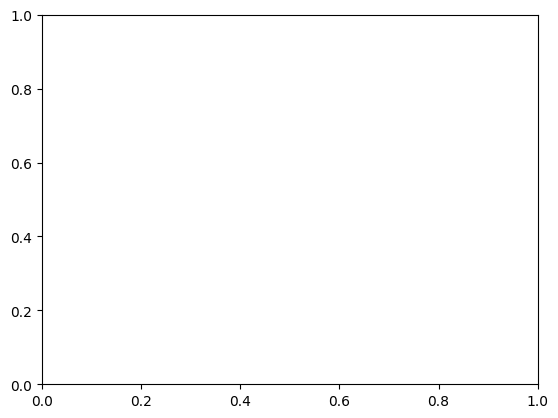

In [ ]:
data = pdf.filter( variable=["Primary Energy|renewable|solar",
                                            "Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs, region = 'Canada')

data.plot.stack(title = 'Primary Energy by fuel - Baseline Scenario')
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [ ]:
i_feed = ['Useful Energy|i_feed|ethanol_fs|M1', 'Useful Energy|i_feed|gas_fs|M1',
         'Useful Energy|i_feed|loil_fs|M1', 'Useful Energy|i_feed|methanol_fs|M1']

transport = ['Useful Energy|transport|coal_trp|M1',
            'Useful Energy|transport|elec_trp|M1',
            'Useful Energy|transport|eth_fc_trp|M1',
            'Useful Energy|transport|eth_ic_trp|M1',
            'Useful Energy|transport|foil_trp|M1',
            'Useful Energy|transport|gas_trp|M1',
            'Useful Energy|transport|h2_fc_trp|M1',
            'Useful Energy|transport|loil_trp|M1',
            'Useful Energy|transport|meth_fc_trp|M1',
            'Useful Energy|transport|meth_ic_trp|M1']


i_spec = ['Useful Energy|i_spec|h2_fc_I|M1',
          'Useful Energy|i_spec|sp_coal_I|M1',
          'Useful Energy|i_spec|sp_el_I|M1',
          'Useful Energy|i_spec|sp_eth_I|M1',
          'Useful Energy|i_spec|sp_liq_I|M1',
          'Useful Energy|i_spec|sp_meth_I|M1']

i_therm =   ['Useful Energy|i_therm|biomass_i|M1',
            'Useful Energy|i_therm|coal_i|M1',
            'Useful Energy|i_therm|elec_i|M1',
            'Useful Energy|i_therm|eth_i|M1',
            'Useful Energy|i_therm|foil_i|M1',
            'Useful Energy|i_therm|gas_i|M1',
            'Useful Energy|i_therm|h2_fc_I|M1',
            'Useful Energy|i_therm|h2_i|M1',
            'Useful Energy|i_therm|heat_i|M1',
            'Useful Energy|i_therm|hp_el_i|M1',
            'Useful Energy|i_therm|hp_gas_i|M1',
            'Useful Energy|i_therm|loil_i|M1',
            'Useful Energy|i_therm|meth_i|M1',
            'Useful Energy|i_therm|solar_i|M1']
rc_spec = ['Useful Energy|rc_spec|h2_fc_RC|M1',
          'Useful Energy|rc_spec|sp_el_RC|M1']

rc_therm = ['Useful Energy|rc_therm|biomass_rc|M1',
            'Useful Energy|rc_therm|coal_rc|M1',
            'Useful Energy|rc_therm|eth_rc|M1',
            'Useful Energy|rc_therm|foil_rc|M1',
            'Useful Energy|rc_therm|gas_rc|M1',
            'Useful Energy|rc_therm|h2_fc_RC|M1',
            'Useful Energy|rc_therm|h2_rc|M1',
            'Useful Energy|rc_therm|heat_rc|M1',
            'Useful Energy|rc_therm|hp_el_rc|M1',
            'Useful Energy|rc_therm|hp_gas_rc|M1',
            'Useful Energy|rc_therm|loil_rc|M1',
            'Useful Energy|rc_therm|meth_rc|M1',
            'Useful Energy|rc_therm|solar_rc|M1']

biom = ['Useful Energy|non-comm|biomass_nc|M1']

In [ ]:
df_useful = pyam_df.copy()
# df_useful.aggregate(
#     "Useful Energy|non-Commercial biomass",
#     components=biom,
#     append=True
# )

df_useful.aggregate(
    "residential/commercial thermal",
    components=rc_therm,
    append=True
)

df_useful.aggregate(
    "residential/commercial specific",
    components=rc_spec,
    append=True
)

df_useful.aggregate(
    "industrial thermal",
    components=i_therm,
    append=True
)

df_useful.aggregate(
    "industrial specific",
    components=i_spec,
    append=True
)

df_useful.aggregate(
    "industrial feedstock",
    components=i_feed,
    append=True
)

df_useful.aggregate(
    "transport",
    components=i_therm,
    append=True
)


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

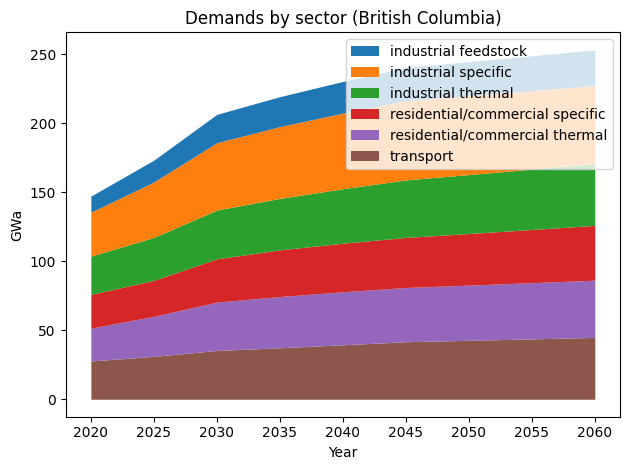

In [ ]:
data = df_useful.filter( variable=[
    "non-Commercial biomass",
    "residential/commercial thermal",
    "residential/commercial specific",
    "industrial thermal",
    "industrial specific",
    "industrial feedstock",
    "transport"],
              year = plotyrs, region = 'BritishColumbia')


data.plot.stack(title = 'Demands by sector (British Columbia)', legend={"loc": "outside right"})
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [ ]:
cement = ['Emissions|CO2|cement_CO2|M1']
coal = ['Emissions|CO2|coal_extr_ch4|M1',
        'Emissions|CO2|coal_extr|M1',
        'Emissions|CO2|coal_imp|M1']
foil = ['Emissions|CO2|foil_imp|M1']
gas = ['Emissions|CO2|gas_extr_1|M1',
        'Emissions|CO2|gas_extr_2|M1',
        'Emissions|CO2|gas_extr_3|M1',
        'Emissions|CO2|gas_extr_4|M1',
        'Emissions|CO2|gas_extr_5|M1',
        'Emissions|CO2|gas_extr_6|M1'
        ]
lignite = ['Emissions|CO2|lignite_extr|M1']
loil = ['Emissions|CO2|loil_imp|M1']
meth_ccs = ['Emissions|CO2|meth_coal_ccs|M1']
oil = ['Emissions|CO2|oil_extr_1_ch4|M1',
    'Emissions|CO2|oil_extr_1|M1',
    'Emissions|CO2|oil_extr_2_ch4|M1',
    'Emissions|CO2|oil_extr_2|M1',
    'Emissions|CO2|oil_extr_3_ch4|M1',
    'Emissions|CO2|oil_extr_3|M1',
    'Emissions|CO2|oil_extr_4_ch4|M1',
    'Emissions|CO2|oil_extr_4|M1',
    'Emissions|CO2|oil_extr_5|M1',
    'Emissions|CO2|oil_extr_6|M1',
    'Emissions|CO2|oil_extr_7|M1']

oil_trade = ['Emissions|CO2|foil_imp|M1',
             'Emissions|CO2|loil_exp|M1',
            'Emissions|CO2|loil_imp|M1',
             'Emissions|CO2|oil_imp|M1']
       
gas_trade = ['Emissions|CO2|LNG_exp|M1',
            'Emissions|CO2|LNG_imp|M1',
            'Emissions|CO2|gas_imp|M1']
            #'Emissions|CO2|LNG_exp|M1']

In [ ]:
df_emis_b = pyam_df.filter(variable = 'Emissions|CO2|*',year = plotyrs)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [ ]:
df_emis_b.to_csv('emissions.csv')

In [ ]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

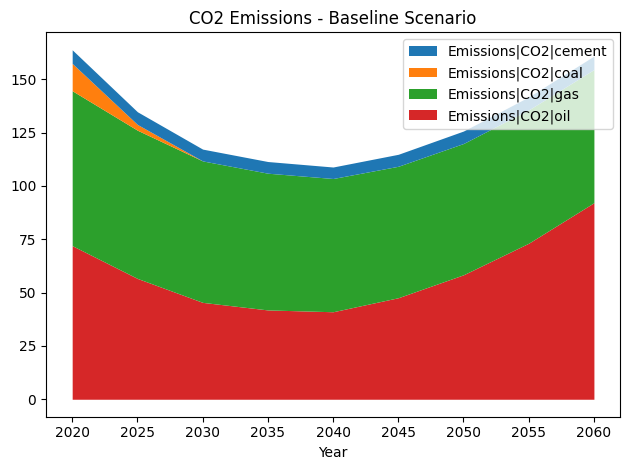

In [ ]:
data = df_emis.filter( variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement"],
    # "Emissions|CO2|oil trade",
    # "Emissions|CO2|gas trade"],
              year = plotyrs, region = 'Canada')

data.plot.stack(title = 'CO2 Emissions - Baseline Scenario')
plt.legend(loc=1)
plt.tight_layout()
plt.show()

In [ ]:
df_emis.aggregate('Emissions|*').timeseries()

In [ ]:

coal = ['Total Costs|coal_adv',
        'Total Costs|coal_adv_ccs',
        'Total Costs|coal_bal',
        'Total Costs|coal_exp',
        'Total Costs|coal_extr',
        'Total Costs|coal_extr_ch4',
        'Total Costs|coal_gas',
        'Total Costs|coal_hpl',
        'Total Costs|coal_i',
        'Total Costs|coal_imp',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
        'Total Costs|coal_rc',
        'Total Costs|coal_ppl',
        'Total Costs|coal_ppl_u',
       'Total Costs|coal_t_d',
       'Total Costs|syn_liq',
        'Total Costs|meth_coal',
       'Total Costs|lignite_extr']
biomass = ['bio_hpl', 'bio_ppl',
          'Total Costs|liq_bio']


elec = ['Total Costs|elec_exp',
        'Total Costs|elec_i',
        'Total Costs|elec_imp',
        'Total Costs|elec_t_d',
        'Total Costs|elec_trp']

oil = ['Total Costs|foil_i',
    'Total Costs|foil_imp',
    'Total Costs|foil_ppl',
    'Total Costs|oil_extr_1'
    'Total Costs|oil_extr_1_ch4'
    'Total Costs|oil_extr_2',
    'Total Costs|oil_extr_3',
    'Total Costs|oil_extr_4',
    'Total Costs|oil_extr_5',
    'Total Costs|oil_extr_6',
    'Total Costs|oil_extr_7',
    'Total Costs|oil_extr_2_ch4',
    'Total Costs|oil_extr_3_ch4',
    'Total Costs|loil_cc',
    'Total Costs|loil_ppl']
gas = ['Total Costs|gas_bal',
    'Total Costs|gas_bio',
    'Total Costs|gas_cc',
    'Total Costs|gas_cc_ccs',
    'Total Costs|gas_ct',
    'Total Costs|gas_extr_1',
    'Total Costs|gas_extr_2',
    'Total Costs|gas_extr_3',
    'Total Costs|gas_extr_4',
    'Total Costs|gas_extr_5',
    'Total Costs|gas_extr_6',
    'Total Costs|gas_extr_mpen',
    'Total Costs|gas_fs',
    'Total Costs|gas_hpl',
    'Total Costs|gas_i',
    'Total Costs|gas_imp',
    'Total Costs|gas_ppl',
    'Total Costs|gas_rc',
    'Total Costs|gas_t_d',
    'Total Costs|gas_t_d_ch4',
    'Total Costs|gas_trp',
      'Total Costs|igcc']

geo_ppl = ['Total Costs|geo_hpl','Total Costs|geo_ppl']

solar = ['Total Costs|solar_i',
        'Total Costs|solar_pv_ppl',
        'Total Costs|solar_rc',
        'Total Costs|solar_th_ppl']

wind = ['Total Costs|wind_curtailment1',
'Total Costs|wind_curtailment2',
'Total Costs|wind_curtailment3',
'Total Costs|wind_ppf',
'Total Costs|wind_ppl']

hydro = ['Total Costs|hydro_hc',
'Total Costs|hydro_lc']

nuclear = ['Total Costs|nuc_lc']


In [ ]:
df_cost = pyam_df.copy()


df_cost.aggregate(
    "Total Costs|coal",
    components=coal,
    append=True
)

df_cost.aggregate(
    "Total Costs|biomass",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|electricity",
    components=elec,
    append=True
)

df_cost.aggregate(
    "Total Costs|oil",
    components=biomass,
    append=True
)

df_cost.aggregate(
    "Total Costs|gas",
    components=gas,
    append=True
)

df_cost.aggregate(
    "Total Costs|geothermal",
    components=geo_ppl,
    append=True
)

df_cost.aggregate(
    "Total Costs|solar",
    components=solar,
    append=True
)

df_cost.aggregate(
    "Total Costs|wind",
    components=wind,
    append=True
)

df_cost.aggregate(
    "Total Costs|hydro",
    components=hydro,
    append=True
)
df_cost.aggregate(
    "Total Costs|nuclear",
    components=nuclear,
    append=True
)

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  return df.groupby(cols).agg(_get_method_func(method))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/aggregation.py:210: FutureWarning: The provided callable <function sum at 0x7fa240d0e440> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "su

In [ ]:
data.unit

['']

In [ ]:
df_cost.timeseries()

2010  \
model            scenario       region  variable                          unit         
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp                0.0   
                                        Capacity Addition|adipic_thermal         0.0   
                                        Capacity Addition|ammonia_secloop        0.0   
                                        Capacity Addition|bio_hpl                0.0   
                                        Capacity Addition|bio_hpl__air           0.0   
...                                                                              ...   
                                Yukon   vom cost|wind_cv2                        0.0   
                                        vom cost|wind_cv3                        0.0   
                                        vom cost|wind_cv4                        0.0   
                                        vom cost|wind_ppf                        0.0   
                                        vom cost|wind_ppl                        0.0   

                                                                                2015  \
model            scenario       region  variable                          unit         
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp                0.0   
                                        Capacity Addition|adipic_thermal         0.0   
                                        Capacity Addition|ammonia_secloop        0.0   
                                        Capacity Addition|bio_hpl                0.0   
                                        Capacity Addition|bio_hpl__air           0.0   
...                                                                              ...   
                                Yukon   vom cost|wind_cv2                        0.0   
                                        vom cost|wind_cv3                        0.0   
                                        vom cost|wind_cv4                        0.0   
                                        vom cost|wind_ppf                        0.0   
                                        vom cost|wind_ppl                        0.0   

                                                                                    2020  \
model            scenario       region  variable                          unit             
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp               0.000000   
                                        Capacity Addition|adipic_thermal        0.000193   
                                        Capacity Addition|ammonia_secloop       0.000000   
                                        Capacity Addition|bio_hpl               0.082997   
                                        Capacity Addition|bio_hpl__air          0.000000   
...                                                                                  ...   
                                Yukon   vom cost|wind_cv2                       0.000000   
                                        vom cost|wind_cv3                       0.000000   
                                        vom cost|wind_cv4                       0.000000   
                                        vom cost|wind_ppf                       0.000000   
                                        vom cost|wind_ppl                       0.000000   

                                                                                   2025  \
model            scenario       region  variable                          unit            
MESSAGEix-Canada High Tech Cost Alberta Capacity Addition|LNG_exp               0.00000   
                                        Capacity Addition|adipic_thermal        0.00031   
                                        Capacity Addition|ammonia_secloop       0.00000   
                                        Capacity Addition|bio_hpl               0.00000   
                                        Capacit

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:466: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  pd.concat([_df, _rows.loc[_rows.index.difference(_df.index)]])
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/plotting.py:485: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  _df_pos = _df.applymap(lambda x: max(x, 0))
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packa

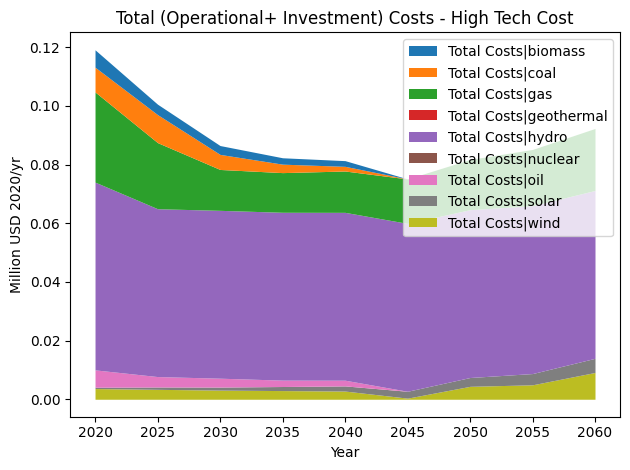

In [ ]:
data = df_cost.filter( variable=
    ["Total Costs|coal","Total Costs|biomass",
    # "Total Costs|electricity",
    "Total Costs|oil",
    "Total Costs|gas",
    "Total Costs|geothermal",
    "Total Costs|solar",
    "Total Costs|wind",
    "Total Costs|hydro",
    "Total Costs|nuclear"],
              year = plotyrs, region = 'Canada')
data.convert_unit("", to="million USD/yr", factor=0.000001, inplace = True)

data.plot.stack(title = 'Total (Operational+ Investment) Costs - High Tech Cost')
plt.legend(loc=1)
plt.ylabel('Million USD 2020/yr')
plt.tight_layout()

plt.show()


Now making another scenario cloned from baseline to add other policies. 

Policy No. 1
Baseline - NDC 
Implement Canada's commitments 


In [122]:
technologies = [
    # "hp_el_rc",
    # "hp_gas_rc",
    # "hp_el_i",
    # "hp_gas_i",
    # "solar_pv_RC",
    # "solar_curtailment1",
    # "solar_cv1",
    "solar_pv_ppl",
    # "solar_res1",
    "solar_th_ppl",
    # "csp_sm3_res",
    # "csp_sm3_ppl",
    # "csp_sm1_res",
    # "csp_sm1_ppl",
    # "wind_curtailment1",
    "wind_cv1",
    "wind_ppl",
    "wind_res1",
    "wind_ppf",
    "wind_ref1",
    "stor_ppl",
    "h2_elec",
    "h2_smr_ccs",
    "bio_istig_ccs",
    "h2_mix",
    "glb_lh2_imp",
    "h2_bio_ccs",
    "h2_co2_scrub",
    "h2_coal",
    "h2_coal_ccs",
    "h2_liq",
    "h2_smr",
    "h2_t/d",
    "h2b_co2_scrub",
    # "lh2_bal",
    "lh2_exp",
    "lh2_imp",
    "lh2_regas",
    "lh2_t/d",
    # "h2_i",
    # "h2_fc_I",
    # "h2_rc",
    # "h2_fc_RC",
    # "h2_fc_trp",
    "LH2_bunker",
    "coal_adv_ccs",
    "gas_cc_ccs",
    "igcc_ccs",
    "cement_co2scr",
    "eth_bio_ccs",
    "liq_bio_ccs",
    "meth_coal_ccs",
    "meth_ng_ccs",
    "syn_liq_ccs",
    "cfc_co2scr"
]


In [124]:
msgbas = scen1.clone(modelName, 'netzero_low_cost',
                     keep_solution=False)
df_inv = msgbas.par('inv_cost')
df_var = msgbas.par('var_cost')
df_fix = msgbas.par('fix_cost')
df_inv.loc[df_inv['technology'].isin(technologies), 'value'] *=0.9
df_var.loc[df_var['technology'].isin(technologies), 'value'] *=0.9
df_fix.loc[df_fix['technology'].isin(technologies), 'value'] *=0.9

msgbas.check_out()
msgbas.add_par('inv_cost', df_inv)
msgbas.add_par('fix_cost', df_fix)
msgbas.add_par('var_cost', df_var)
msgbas.commit('Decreasing costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msgbas.model + '__' + msgbas.scenario + '__v' + str(msgbas.version)
msgbas.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 06/11/24 10:26:08 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__netzero_low_cost__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__netzero_low_cost__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__netzero_low_cost__v1.gdx
Licensee: Small MUD - 5 

2024-06-11 10:27:35,008 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-06-11 10:27:35,016 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [126]:

unit_correct = True  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060
from_excel = False
#%% Generating reporter
rep = Reporter.from_scenario(msgbas, units={"apply": {"var_cost": "","inv_cost": "", "fix_cost": ""}})
report = rep.get('message::default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()
    
report_df = report.timeseries()
report_df.reset_index(inplace=True)
report_df.columns = report_df.columns.astype(str)
report_df.columns = report_df.columns.str.title()
# Plotted years
years = msg.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
# c = report_df.select_dtypes(include=[np.number]) * 8.76
# report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = pd.concat([out_flows , in_flows])
report_df['Model'] = 'MESSAGEix-Canada'
report_df['Scenario'] = 'Net Zero'
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP_NEW|new capacity|', 'Capacity Addition|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('inv cost|', 'Capital Cost|', regex = False)
report_df['Region'] = report_df['Region'].apply(lambda x: x.split('|')[0])
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
variable = pyam_df.variable
pyam_df.aggregate_region(variable, append = True)
pyam_df.rename({'region': {'World': 'Canada'}}, inplace=True)
pdf = pyam_df.copy()
pdf.to_csv('MESSAGE_CANADA_provincial_netzero_lowcost_v1.csv')


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
input: mixed units ['GWa', '-', '%'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-p

In [125]:
msghigh = scen1.clone(modelName, 'netzero_high_cost',
                     keep_solution=False)
df_inv = msghigh.par('inv_cost')
df_var = msghigh.par('var_cost')
df_fix = msghigh.par('fix_cost')
df_inv.loc[df_inv['technology'].isin(technologies), 'value'] *=1.1
df_var.loc[df_var['technology'].isin(technologies), 'value'] *=1.1
df_fix.loc[df_fix['technology'].isin(technologies), 'value'] *=1.1

msghigh.check_out()
msghigh.add_par('inv_cost', df_inv)
msghigh.add_par('fix_cost', df_fix)
msghigh.add_par('var_cost', df_var)
msghigh.commit('Decreasing costs of innovative techs by 10%')
# Exporting the built model (Scenario) to GAMS with an optional case name
caseName = msghigh.model + '__' + msghigh.scenario + '__v' + str(msghigh.version)
msghigh.solve(model='MESSAGE', case=caseName, solve_options={'lpmethod': '4'})

--- Warning: The GAMS version [45.1.0] differs from the API version [24.8.3].
--- Job MESSAGE_run.gms Start 06/11/24 10:31:00 45.1.0 88bbff72 DEX-DEG x86 64bit/macOS
--- Applying:
    /Library/Frameworks/GAMS.framework/Versions/45/Resources/gmsprmun.txt
--- GAMS Parameters defined
    Input /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/MESSAGE_run.gms
    ScrDir /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/225a/
    SysDir /Library/Frameworks/GAMS.framework/Versions/45/Resources/
    LogOption 4
    --in /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/data/MsgData_MESSAGEix_CA_provincial__netzero_high_cost__v1.gdx
    --out /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgOutput_MESSAGEix_CA_provincial__netzero_high_cost__v1.gdx
    --iter /Users/muhammadawais/Documents/GitHub/message_ix/message_ix/model/output/MsgIterationReport_MESSAGEix_CA_provincial__netzero_high_cost__v1.gdx
Licensee: Small MUD -

2024-06-11 10:32:36,379 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'I' not found in gdx!
2024-06-11 10:32:36,382 ERROR at.ac.iiasa.ixmp.objects.Scenario:1691 - variable 'C' not found in gdx!


In [128]:

unit_correct = True  # unit s must be corrected to run this script
from_excel = False
min_year = 2015
max_year = 2060
from_excel = False
#%% Generating reporter
rep = Reporter.from_scenario(msghigh, units={"apply": {"var_cost": "","inv_cost": "", "fix_cost": ""}})
report = rep.get('message::default') # in fact, only in = input x ACT, out = output x ACT is needed

if from_excel:
    # Read default report
    report_df = pd.read_csv('MESSAGE_NO_example_default_report.csv')
else:
# Or if trying another country model, execute the next 4:
    report_df = report.timeseries()
    report_df.reset_index(inplace=True)
    report_df.columns = report_df.columns.astype(str)
    report_df.columns = report_df.columns.str.title()
    
report_df = report.timeseries()
report_df.reset_index(inplace=True)
report_df.columns = report_df.columns.astype(str)
report_df.columns = report_df.columns.str.title()
# Plotted years
years = msg.set('year').tolist()
years = [str(x) for x in years if x >= min_year and x <= max_year]

# Create data for Sankey diagrams and plot it using plotly
report_df.fillna(0, inplace = True)

# Convert from GWa to TWh (*8.76)
# c = report_df.select_dtypes(include=[np.number]) * 8.76
# report_df[c.columns] = c

# Drop not necessary years
report_df.columns = report_df.columns.astype(str)
report_df = report_df.drop(report_df.columns.to_series()['2020': str(min_year)],
                           axis=1)

# Identify input and output variables and its flows (provided within the Reporter: in = input x ACT, out = output x ACT)
in_flows = report_df[report_df['Variable'].str.startswith("in|")]
out_flows = report_df[report_df['Variable'].str.startswith("out|")]
all_flows = pd.concat([out_flows , in_flows])
report_df['Model'] = 'MESSAGEix-Canada'
report_df['Scenario'] = 'Net Zero'
report_df["Variable"] = report_df["Variable"].str.replace('emis', 'Emissions', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|final|', 'Final Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|primary|', 'Primary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|secondary|', 'Secondary Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|renewable|', 'Primary Energy|renewable|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('total om cost|', 'Total Costs|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('out|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('in|useful|', 'Useful Energy|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP_NEW|new capacity|', 'Capacity Addition|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('CAP|capacity|', 'Capacity|', regex = False)
report_df["Variable"] = report_df["Variable"].str.replace('inv cost|', 'Capital Cost|', regex = False)
report_df['Region'] = report_df['Region'].apply(lambda x: x.split('|')[0])
import pyam
import matplotlib.pyplot as plt
import pyam
plotyrs = [2020,2025,2030,2035,2040,2045,2050,2055,2060]
pyam_df = pyam.IamDataFrame(report_df)
variable = pyam_df.variable
pyam_df.aggregate_region(variable, append = True)
pyam_df.rename({'region': {'World': 'Canada'}}, inplace=True)
pdf = pyam_df.copy()
pdf.to_csv('MESSAGE_CANADA_provincial_netzero_highcost_v1.csv')


/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
input: mixed units ['GWa', '-', '%'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
emission_factor: mixed units ['tC', '???', 'kg/kWa', '-'] discarded
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-p

In [ ]:
pdf.aggregate(
    "Primary Energy|coal",
    components=coal,
    append=True
)


pdf.aggregate(
    "Primary Energy|renewable|solar",
    components=solar,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|hydro",
    components=hydro,
    append=True
)

pdf.aggregate(
    "Primary Energy|ethanol",
    components=ethanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|methanol",
    components=methanol,
    append=True
)
pdf.aggregate(
    "Primary Energy|Liq. Hydrogen",
    components=lh2,
    append=True
)
pdf.aggregate(
    "Primary Energy|renewable|wind",
    components=wind,
    append=True
)

pdf.aggregate(
    "Primary Energy|renewable|biomass",
    components= biomass_renew,
    append=True
)


pdf.aggregate(
    "Primary Energy|biomass",
    components= biomass,
    append=True
)

pdf.aggregate(
    "Primary Energy|oil",
    components=oil,
    append=True
)

pdf.aggregate(
    "Primary Energy|gas",
    components=gas,
    append=True
)

pdf.aggregate(
    "Primary Energy|LNG",
    components=lng,
    append=True
)

In [ ]:
pdf.filter(variable = 'Primary Energy|oil').timeseries()

In [ ]:
pdf.filter( variable=["Primary Energy|renewable|solar",
                                            #"Primary Energy|LNG",
                                            "Primary Energy|gas",
                                            "Primary Energy|oil",
                                            "Primary Energy|biomass",
                                            "Primary Energy|renewable|wind",
                                            "Primary Energy|Liq. Hydrogen",
                                            "Primary Energy|methanol",
                                            "Primary Energy|ethanol",
                                            "Primary Energy|renewable|hydro",
                                            "Primary Energy|renewable|biomass",
                                            "Primary Energy|methanol",
                                           "Primary Energy|coal"],
              year = plotyrs).stack_plot(total=True,
                                        title = 'Primary Energy by fuel - Baseline Scenario')

In [ ]:
df_emis = pyam_df.copy()


df_emis.aggregate(
    "Emissions|CO2|gas",
    components=gas,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil",
    components=oil,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|coal",
    components=coal,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|cement",
    components=cement,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|oil trade",
    components=oil_trade,
    append=True
)

df_emis.aggregate(
    "Emissions|CO2|gas trade",
    components=gas_trade,
    append=True
)

In [ ]:
df_emis.timeseries()

In [ ]:
df_emis.filter( variable=
    ["Emissions|CO2|gas",
    "Emissions|CO2|oil",
    "Emissions|CO2|coal",
    "Emissions|CO2|cement",
    "Emissions|CO2|oil trade",
    "Emissions|CO2|gas trade"],
              year = plotyrs,region = 'Canada').stack_plot(total=True,
                                         title = 'CO2 Emissions - Baseline Scenario')

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('MESSAGE_CANADA_baselinendc.csv')

In [ ]:
df['Model'].replace('CD_Links_SSP2_R14', 'MESSAGEix-Canada', inplace=True)

In [ ]:
df.head()

In [ ]:
df.to_csv('MESSAGE_CANADA_v1.csv')

In [ ]:
import pandas as pd

In [ ]:
iso = 'CAN'

In [ ]:
# SSP GDP data
ssp_gdp_df = pd.read_excel( str('OECD_SSP_GDP_PPP.xlsx'),
        'OECD_SSP_GDP_PPP',
        header = 0)
ssp_gdp_df = ssp_gdp_df.loc[ (  ssp_gdp_df.Region == iso ) ].reset_index(drop=True)

# SSP population data

ssp_pop_df = pd.read_excel(str('OECD_SSP_POP.xlsx'),
        'OECD_SSP_POP',
        header = 0)
ssp_pop_df = ssp_pop_df.loc[ (  ssp_pop_df.Region == iso  ) ].reset_index(drop=True)

In [ ]:
ssp_pop_df['Scenario'] = ssp_pop_df['Scenario'].str.replace('_v9_130325', '')
ssp_gdp_df['Scenario'] = ssp_gdp_df['Scenario'].str.replace('_v9_130325', '')

In [ ]:
ssp_gdp_df

In [ ]:
import pyam
import matplotlib.pyplot as plt
import pyam

pop_df = pyam.IamDataFrame(ssp_pop_df)
gdp_df = pyam.IamDataFrame(ssp_gdp_df)

In [ ]:
pop_df.head()

In [ ]:
pop_df.plot(color='scenario', title='Population Projections of Canada across SSPs')

In [ ]:
gdp_df.plot(color='scenario', title='GDP Projections of Canada across SSPs')

In [ ]:
mp.add_unit('tCO2/kWa')
mp.add_unit('MtCO2')

In [ ]:
msgbas.set('type_emission')

In [ ]:

msgbas.add_par('bound_emission', ['Canada', 'TCE', 'all', 'cumulative'],
             value=700., unit='MtCO2')

In [ ]:
msgbas.commit('adding emissions bound')

In [ ]:
msgbas.solve()

In [ ]:
msgbas.scenario

In [ ]:
msgbas.par('bound_emission')

In [ ]:
msgCT = msgbas.clone(modelName, 'carbon_bound_by_year','introducing a carbon tax',
                             keep_solution=False)
msgCT.check_out()

In [ ]:
emissions = msgCT.var('EMISS')
emissions

In [ ]:

emission_prices_by_year = msg.var('PRICE_EMISSION')
emission_prices_by_year

In [ ]:

scen_tax = base.clone(model, 'carbon_tax','introducing a carbon tax',
                      keep_solution=False)
scen_tax.check_out()

In [ ]:
years

In [ ]:

base_tax_emission = {
    'node': 'Canada',
    'type_year': years,
    'type_tec': 'all',
    'unit': 'USD/tCO2',
    'type_emission': 'GHG',
    'value': emission_prices.set_index('year').lvl
}

In [ ]:


# in case you need to add the new unit to the platform
mp.add_unit('USD/tCO2')

tax_emission = make_df(base_tax_emission)
scen_tax.add_par('tax_emission', tax_emission)
scen_tax.par('tax_emission')

In [ ]:

scen_tax.commit(comment='setting taxes on emissions')

In [ ]:
scen_tax.var('EMISS', {'node': 'Westeros'})